In [22]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [23]:
data_loc = '../../../data/'
fig_loc = '../figures/'

# intro

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.colors as colors

from astropy.io import fits
import astropy.units as u
import astropy.constants as c

from astropy.modeling import models, fitting
fttr = fitting.LevMarLSQFitter()
gmod = models.Gaussian1D(1.,0.,1.,)

from scipy.optimize import minimize, curve_fit
from scipy.signal import find_peaks

from joblib import Parallel, delayed

from dust_3d_functions import *


In [3]:
ednhfr = fits.open(data_loc+'edenhofer_lbd.fits')[1].data
ednhfr_cm3 = A_to_n(ednhfr*2.8).value

In [4]:
mif = pd.read_csv(data_loc+'mif_tab1_final.csv',delimiter=',')
mi1 = pd.read_csv(data_loc+'mi_tab1.csv',delimiter=',')


table1 = mif#if1 

ds    = table1['d(pc)'].to_numpy().astype('float')
names = table1['Name']

lc = np.nanmean(table1[['l0(°)', 'l1(°)']],axis=1)
bc = np.nanmean(table1[['b0(°)', 'b1(°)']],axis=1)

drs = np.nanmax((np.nanstd(table1[['l0(°)', 'l1(°)']],axis=1),
                 np.nanstd(table1[['b0(°)', 'b1(°)']],axis=1)),axis=0) *u.deg.to(u.rad)*ds

In [9]:
[table1.iloc[i][['l0(°)', 'l1(°)', 'b0(°)', 'b1(°)']].to_numpy().astype('float') for i in [0]]

[array([170., 155., -11.,  -5.])]

In [10]:
table1


,Name,l0(°),l1(°),b0(°),b1(°),d(pc),r(pc)
0,California,170.0,155.0,-11.0,-5.0,450,NaN
1,Camelopardalis,150.0,144.0,16.0,19.0,213,NaN
2,Coalsack,-54.0,-61.0,-4.0,3.0,195,NaN
3,Corona,6.5,-2.5,-27.0,-16.0,156,NaN
4,Hercules,50.0,41.0,7.0,12.0,227,NaN
5,MonR2,-141.0,-149.0,-14.0,-10.0,875,NaN
6,Ophiuchus,-1.0,-9.0,12.0,19.0,150,NaN
7,Orion A,-144.0,-155.0,-21.0,-17.0,425,NaN
8,Orion B,-152.0,-157.0,-17.0,-13.0,415,NaN
9,Perseus,163.0,155.0,-27.0,-15.0,300,NaN


In [13]:
len(table1)

12

# notes 

- instead of t, have the x axis of the right panel be timesd by L where
- only average over values that are within some d_perp when making the d_parl profiles
    - put in as a variable that controls the radius of the tube
- land on a way to select distance ranges
    - look at 'channel' maps along the distance axis
    - or use nicest extinction
    - also a fixed number (either for all, or two thresholds based on the mass)
    - main thing is be able to say why this approach makes sense
    - to use changes in the spine > look at the inclination or someother 0th order property, not the radial profile
- have a way of plotting the spine properties as a function of distance window - change point detection for when there is a jump








clean up + write this out as proto-methods:


- where does cloud start and stop (cross a n threshold) as you scroll down the distance axis - use these two 
    - include an overlay from the traditional 2D maps, to see how the footprint of the cloud defined using diff ns matches the overlaid border

- define the distance range 
- choose a volume density threshold, so within the box, the cloud == the gas above this n
- the spine = defined from the 99th percentile of points that count as the cloud
- once we have a spine, look at how the density varies along it (averaging over a narrow tube)
    - when does the parallel profile stop decreasing monotonically?
    - or : if well fit by a gaussian, use the the width of it
    - independent check - where does the spine run into a background ism ensity
- make the radial profiles + fit rho0,r0,alpha
- R_T

# fig 1

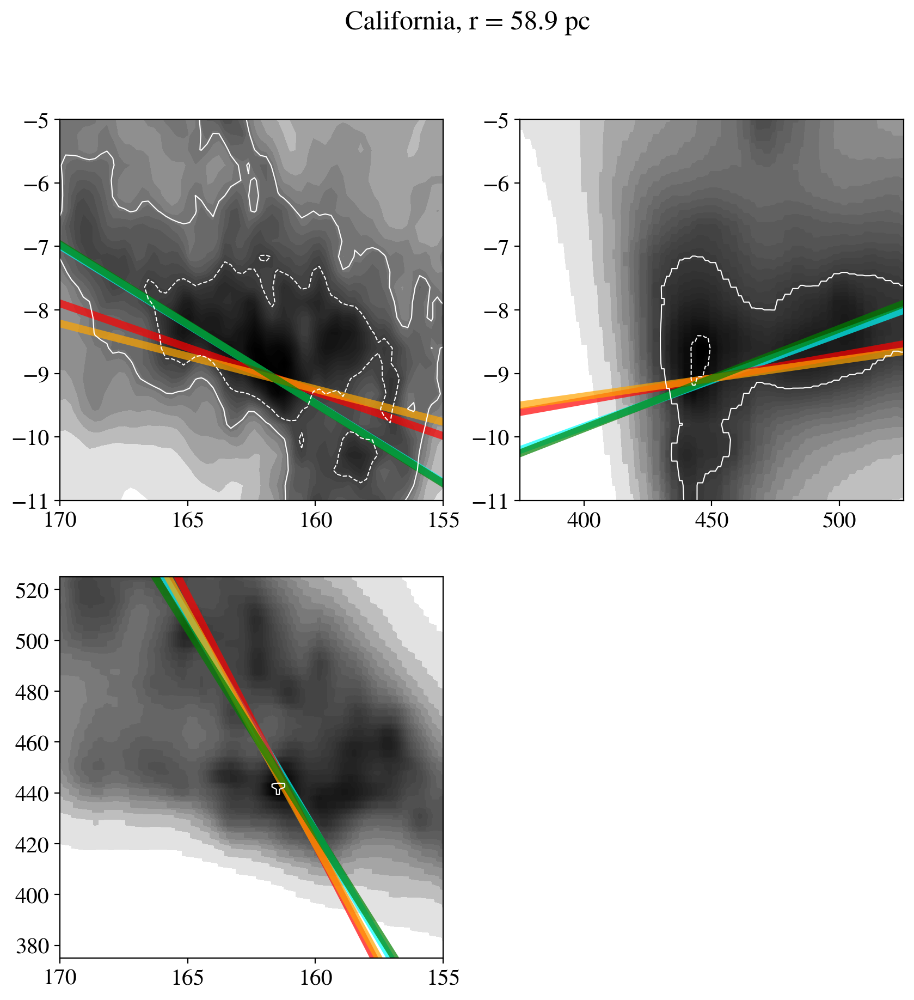

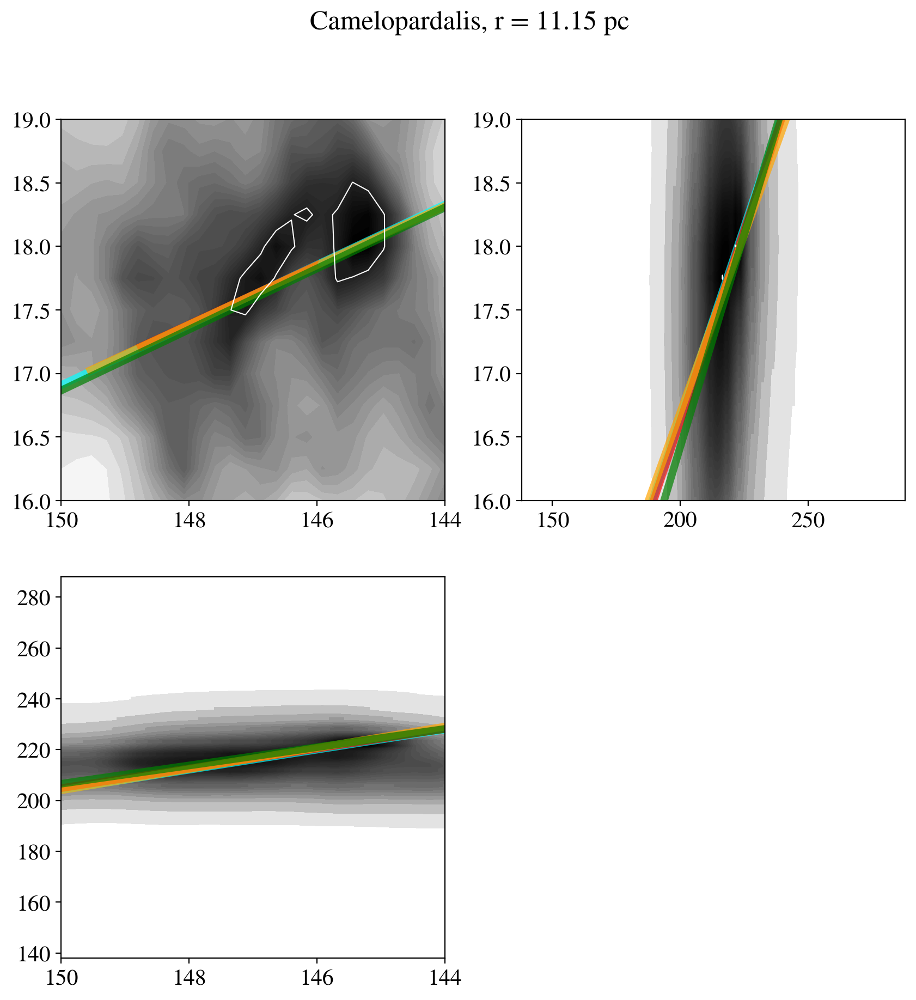

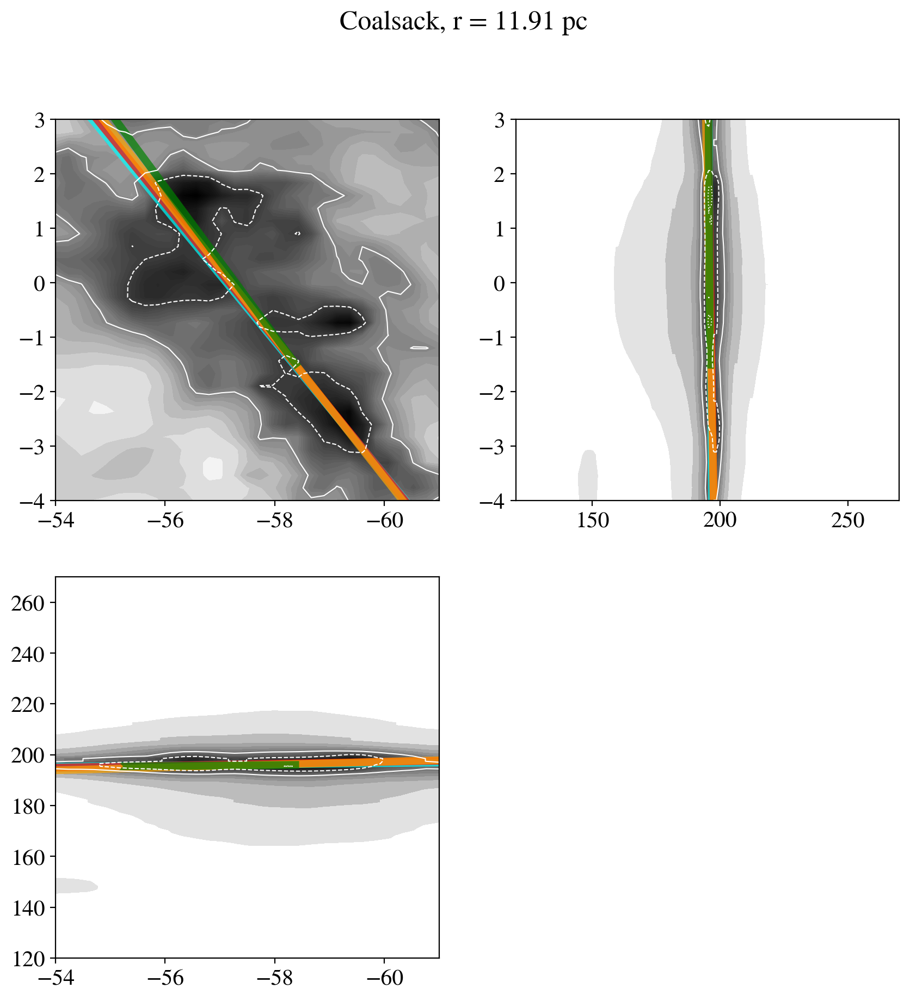

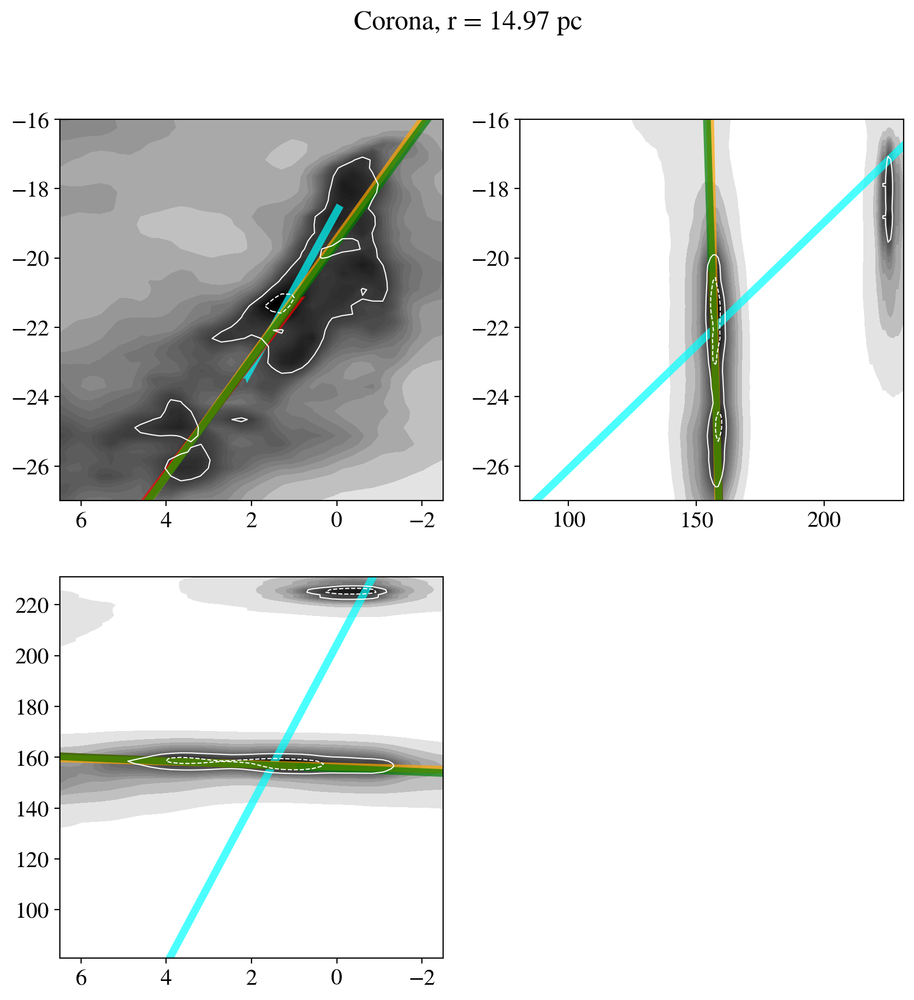

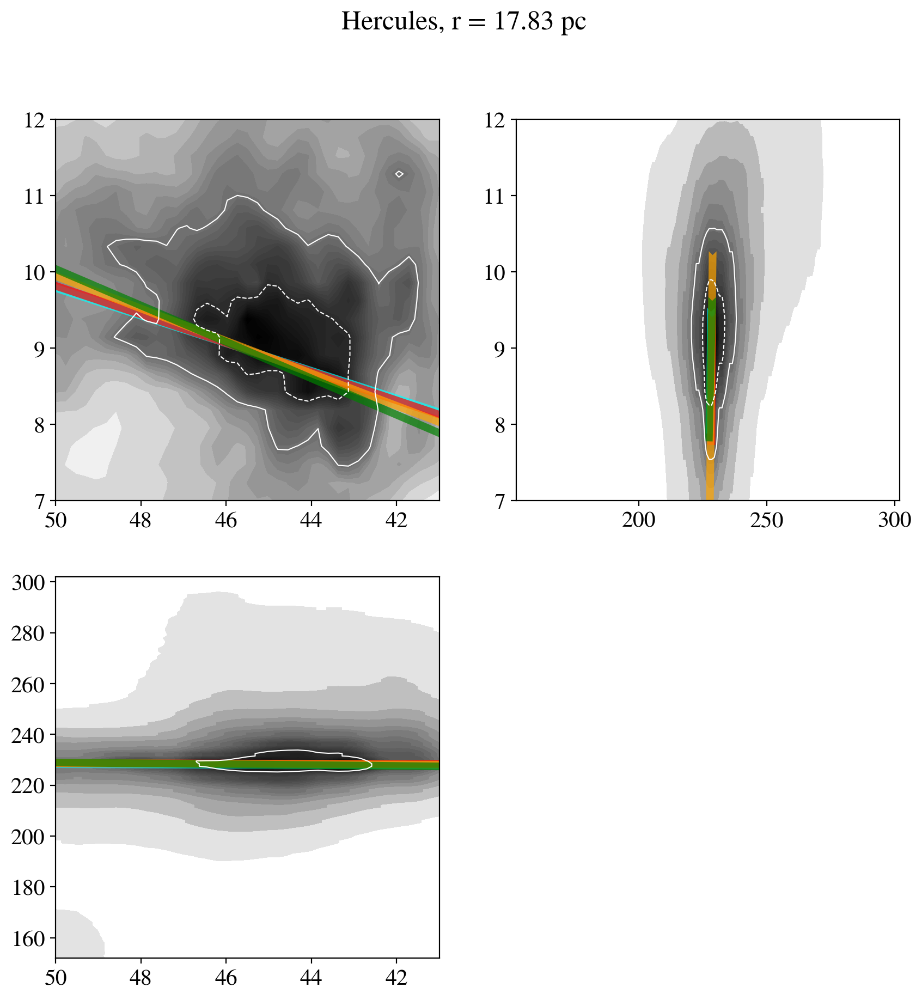

...

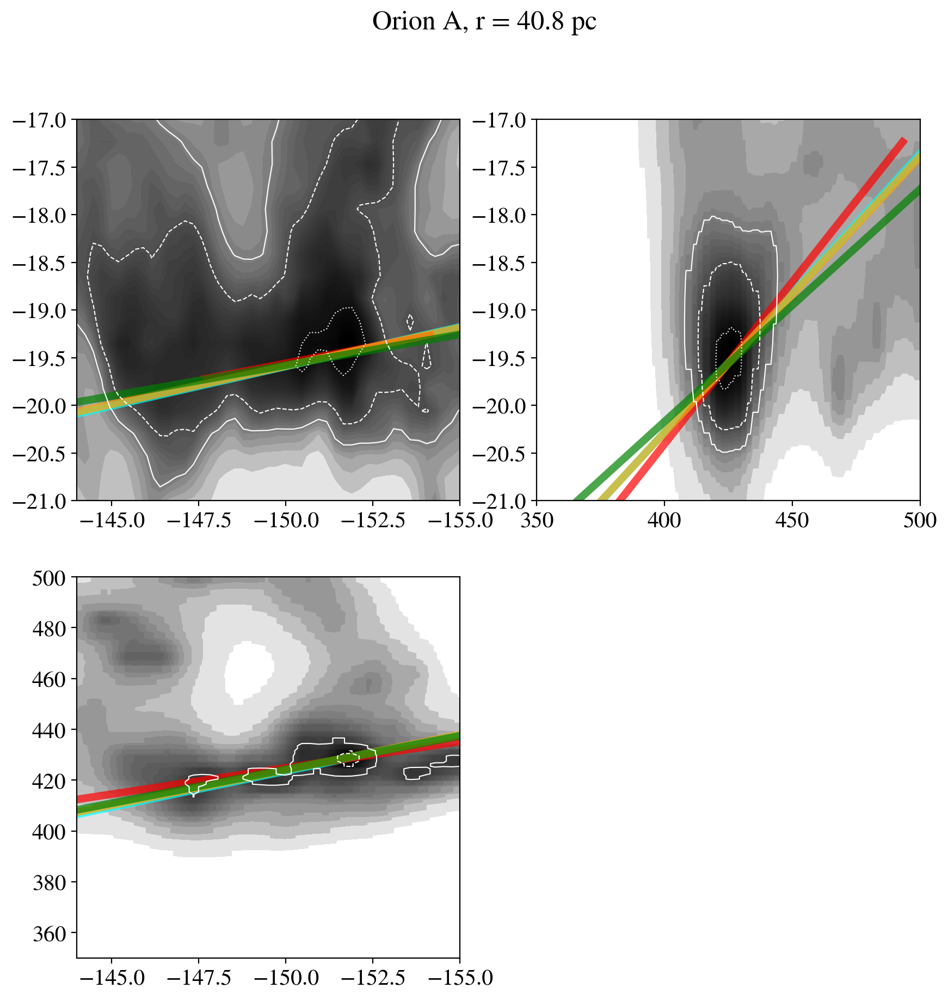

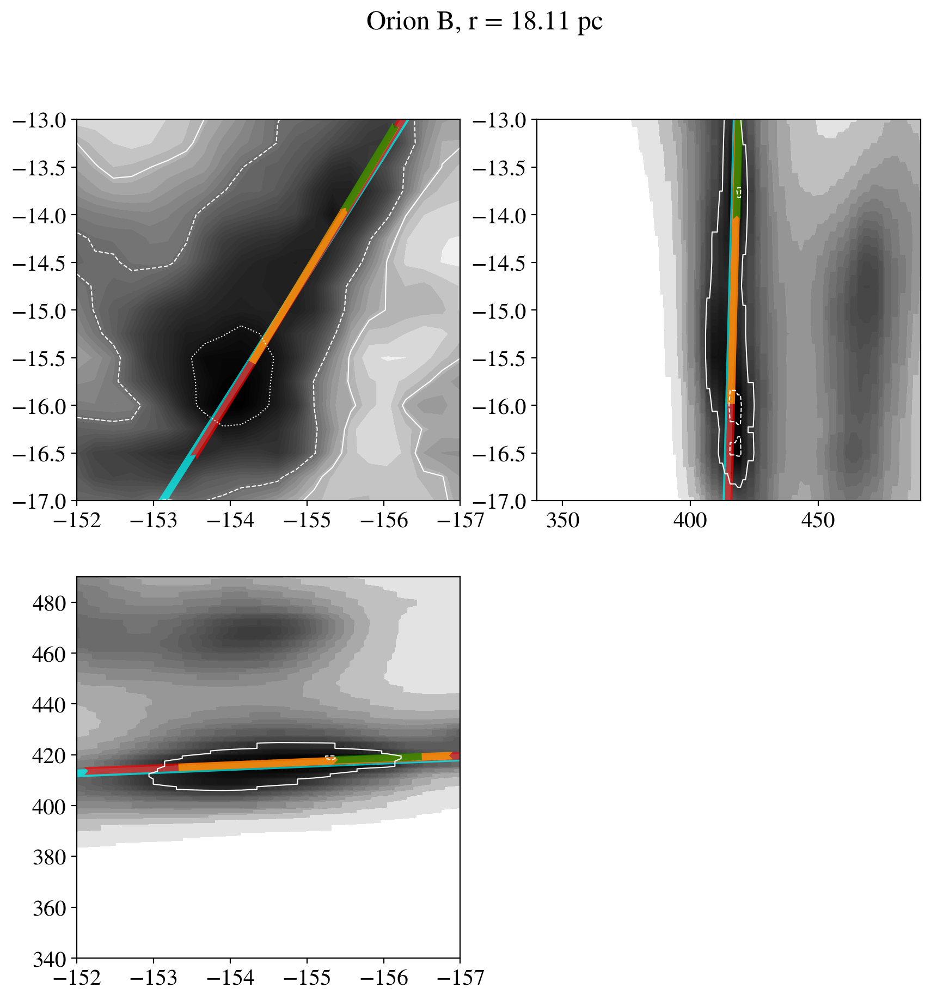

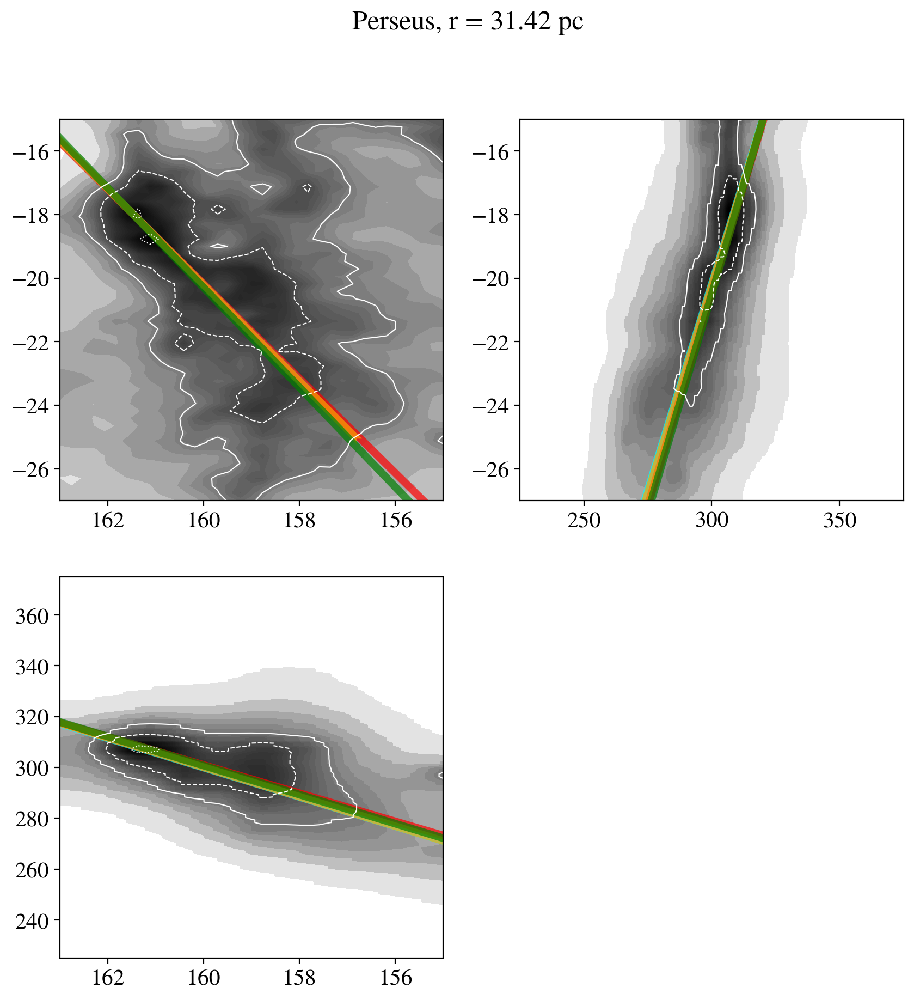

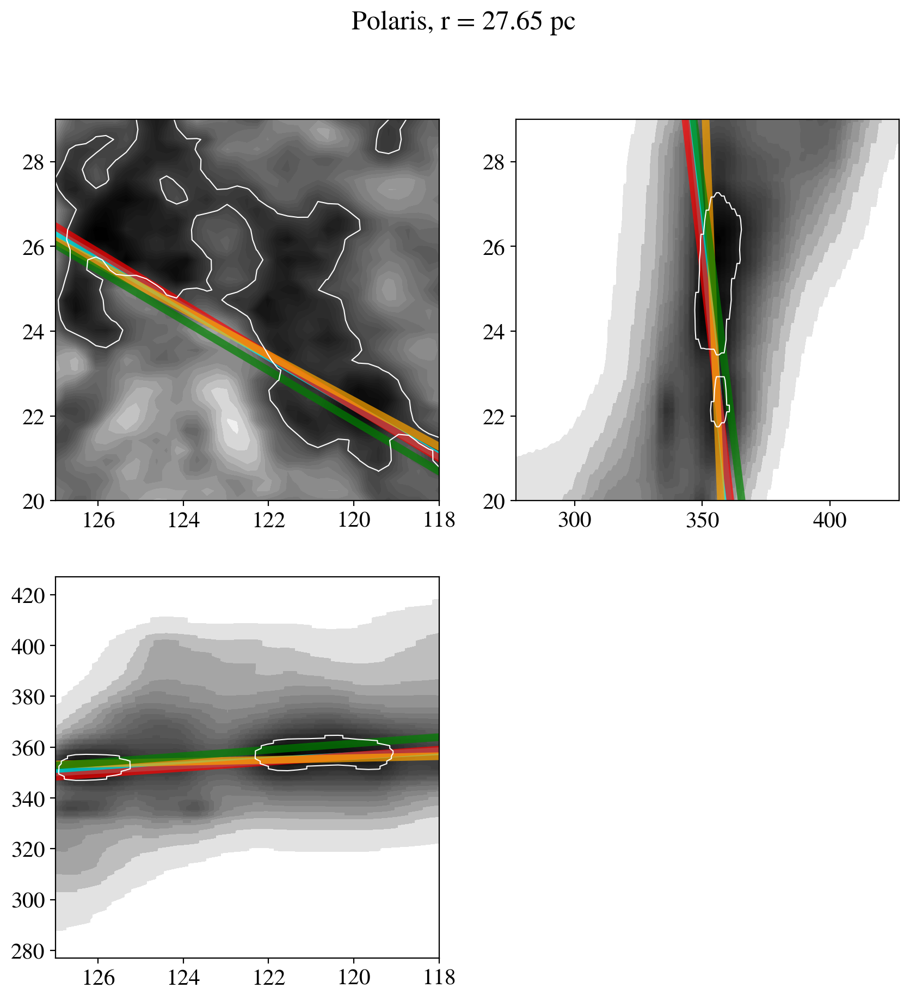

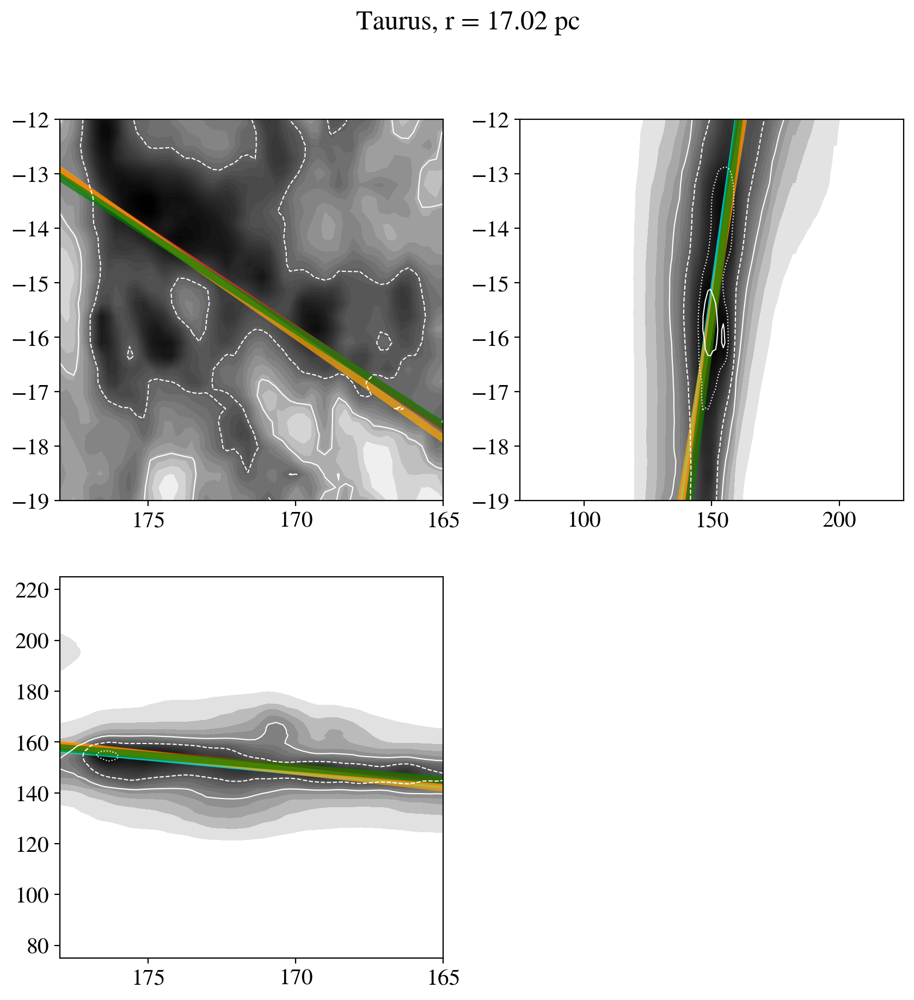

[(array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], d

In [114]:
[(
    
axs,
plot_spine(axs,dict_['spine'],scolor='cyan'),
    
[
plot_spine(axs,dict_['spine'],scolor=clr) 
    for d,clr in zip([3*r,2*r,r],['red','orange','green',])
    for dict_ in [ha(i,ednhfr_cm3,d)]
],
     
plt.show())
    
for i,r in zip(range(12) ,drs)
for dict_ in [ha(i,ednhfr_cm3,75)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],
                             names[i]+', r = '+str(np.around(r,2))+' pc',
                             _,_)]
                            #   b_perp=dict_['b_perp'] ,b_parl=dict_['b_parl'])]

]

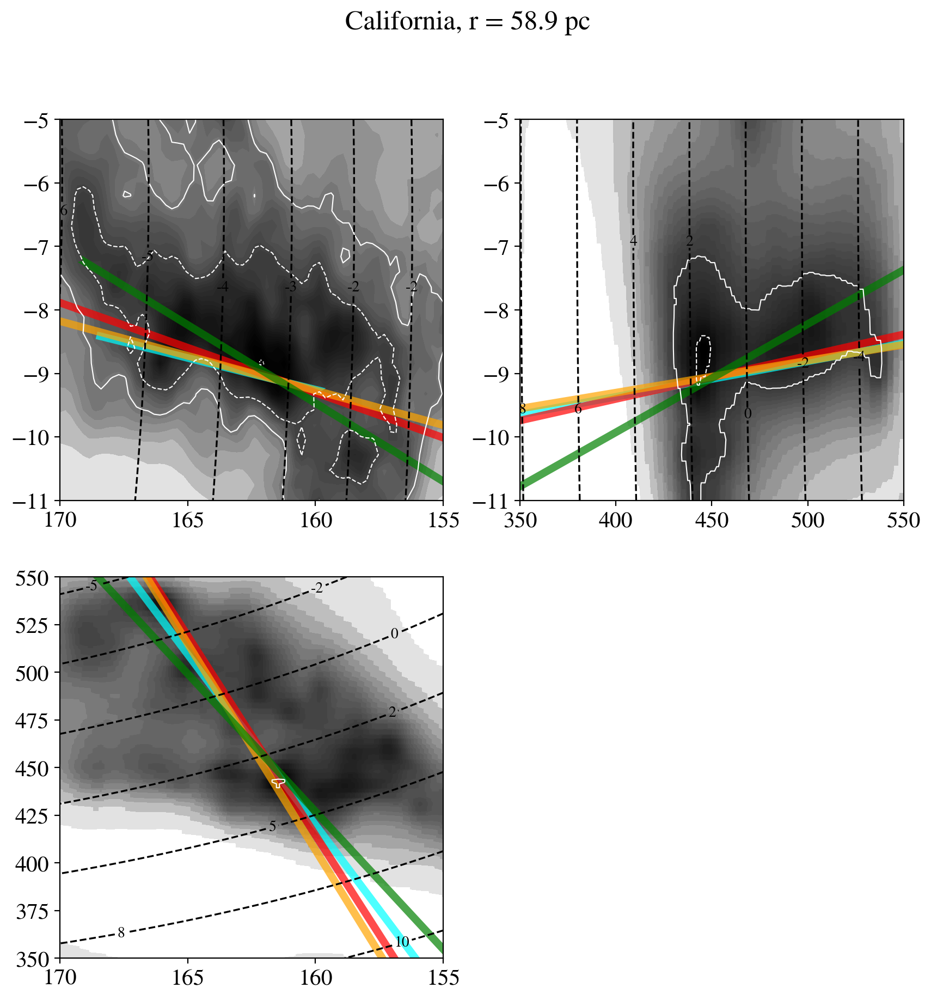

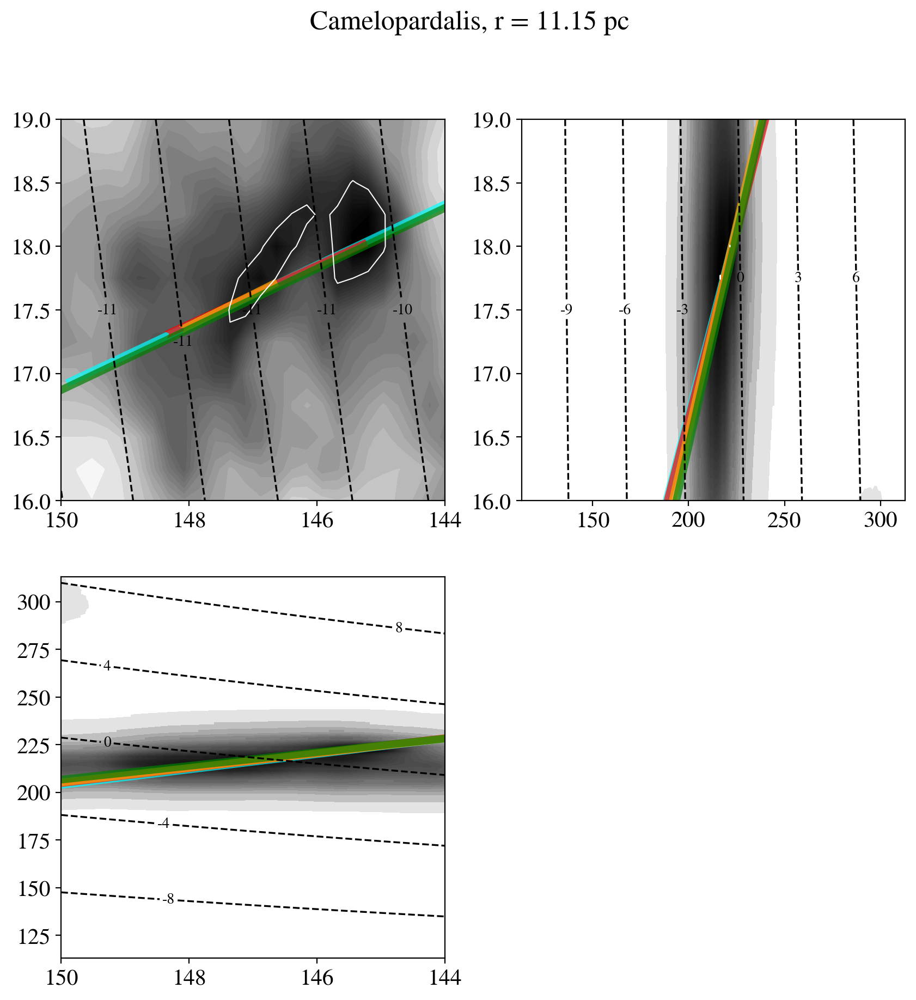

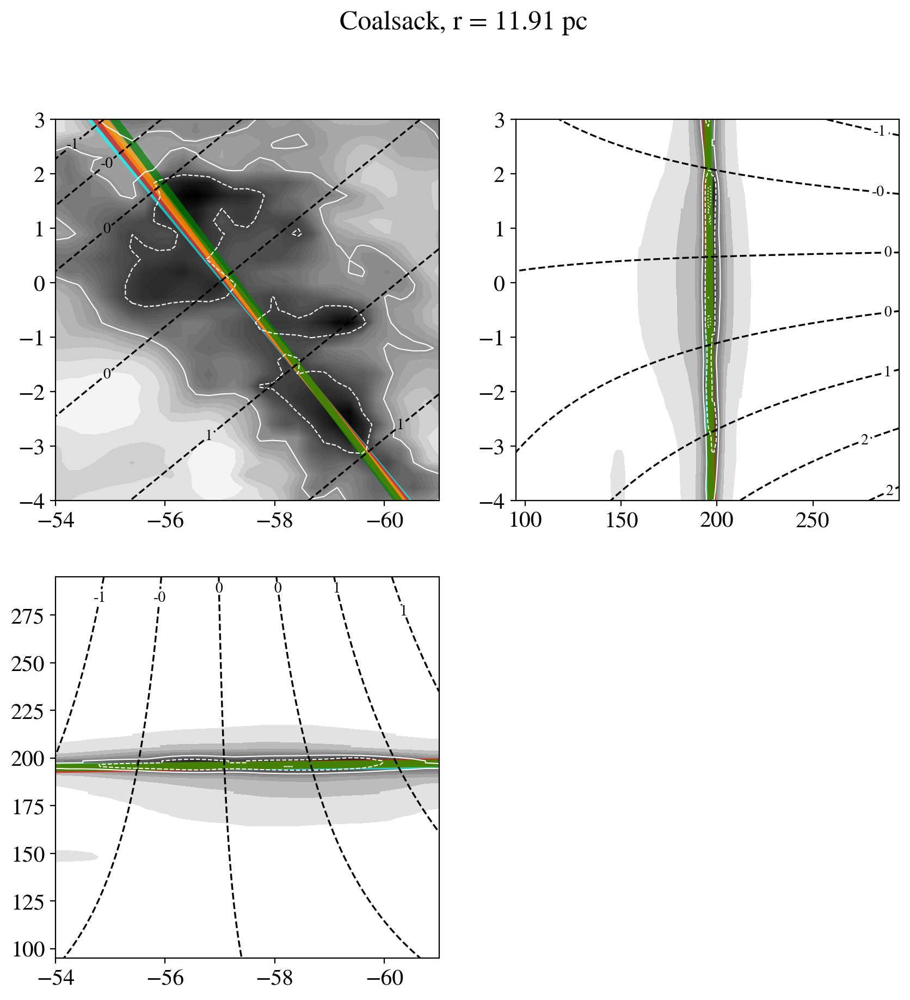

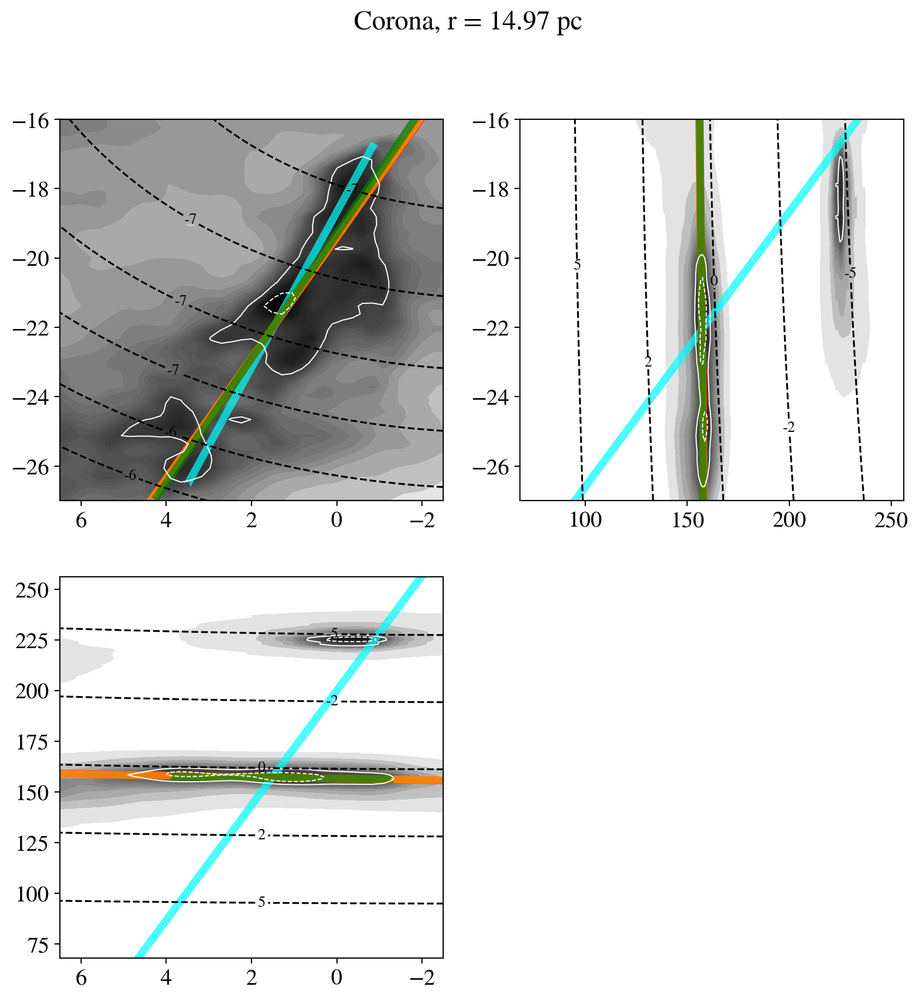

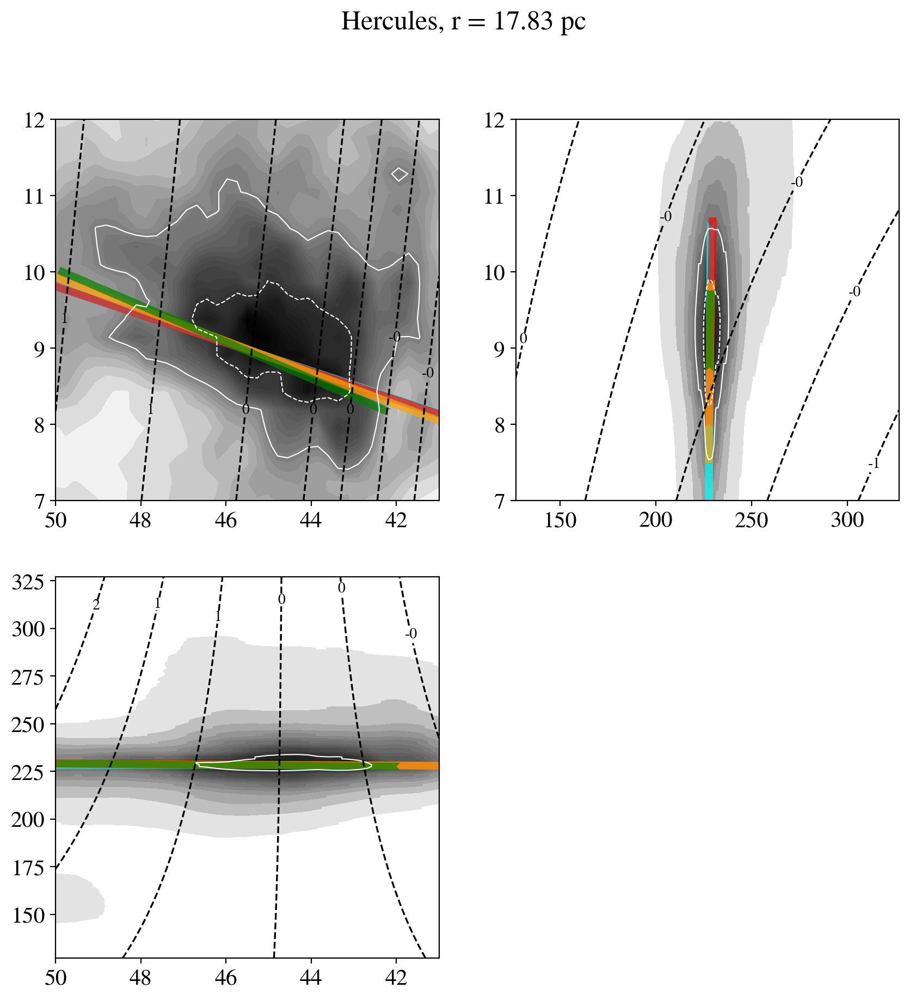

...

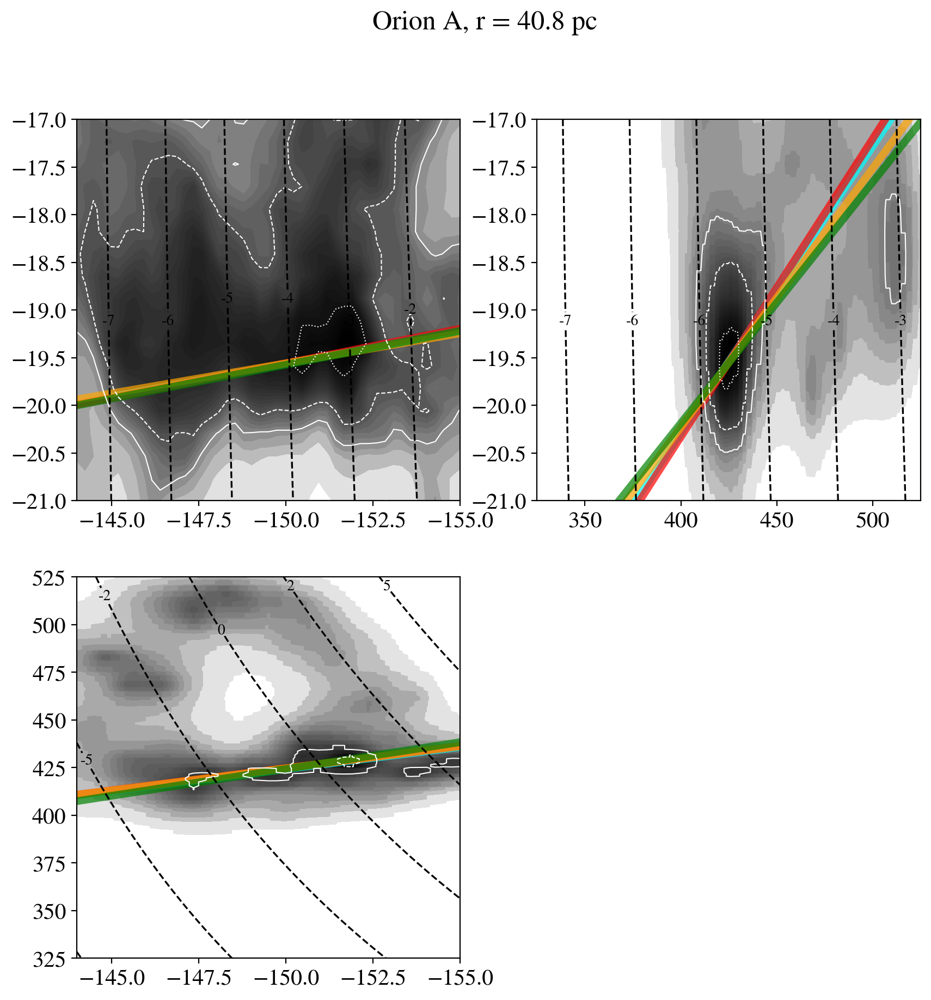

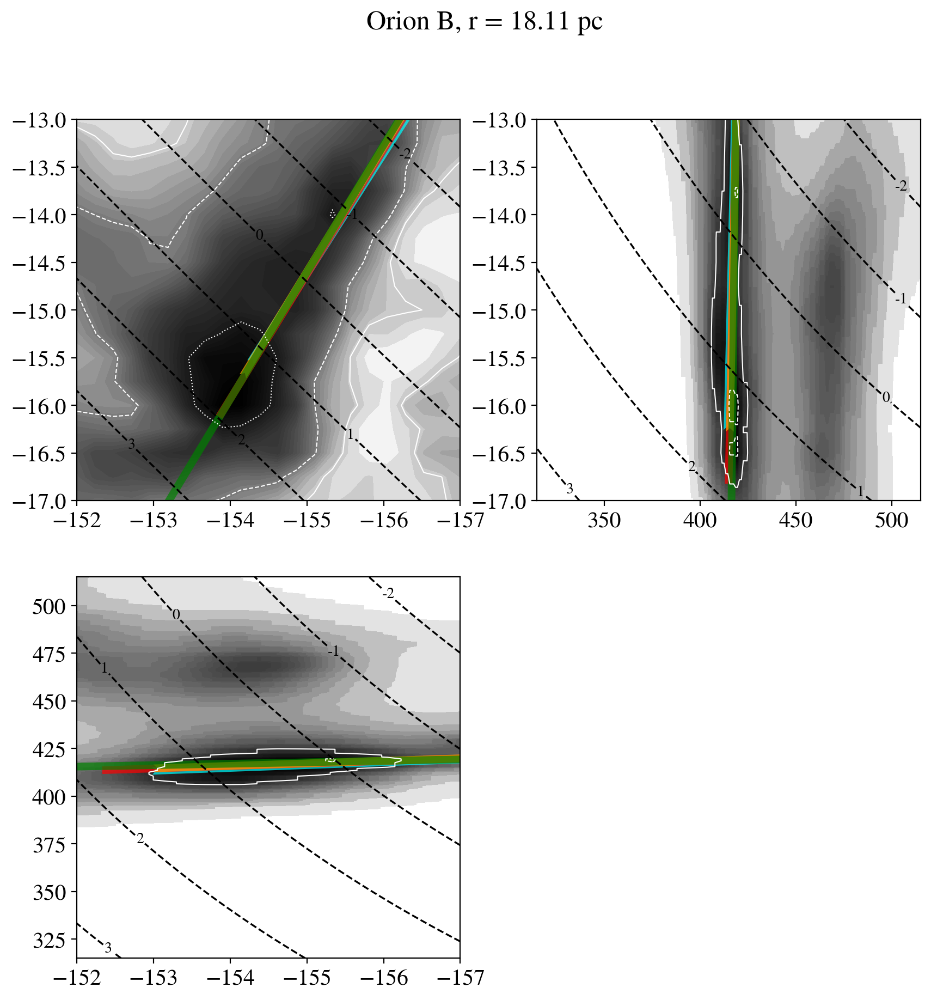

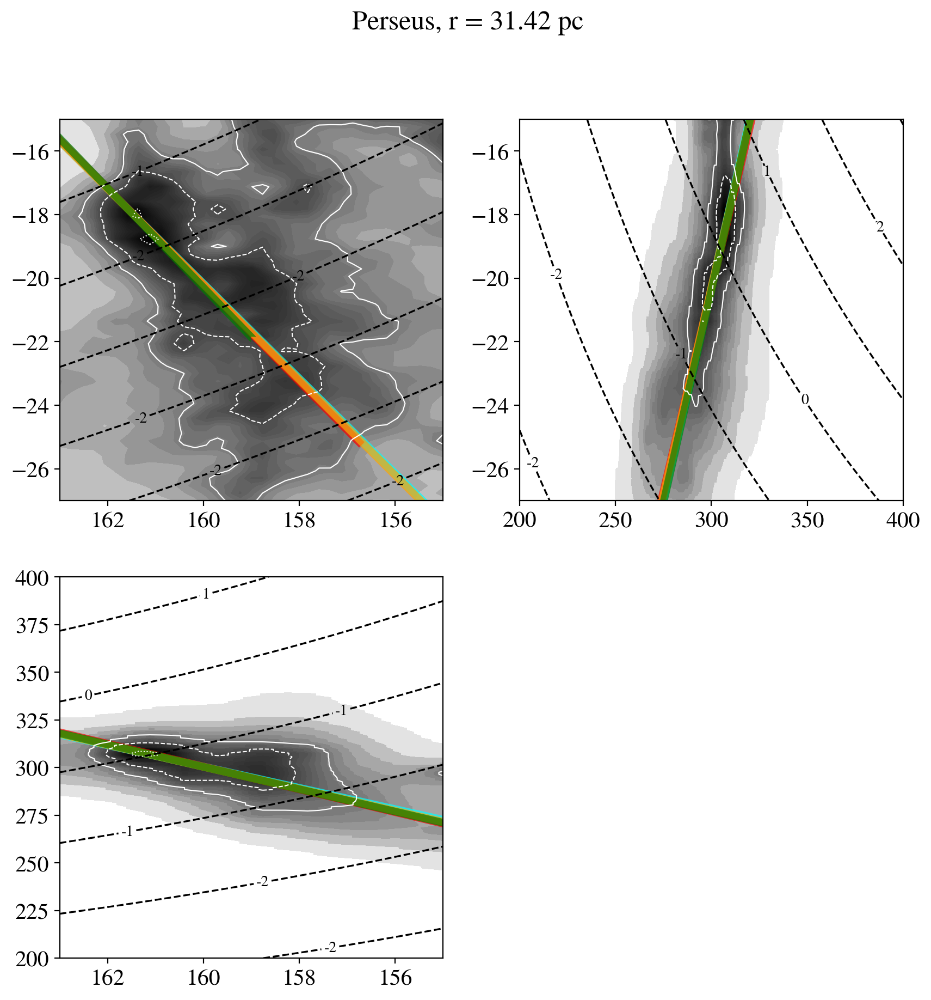

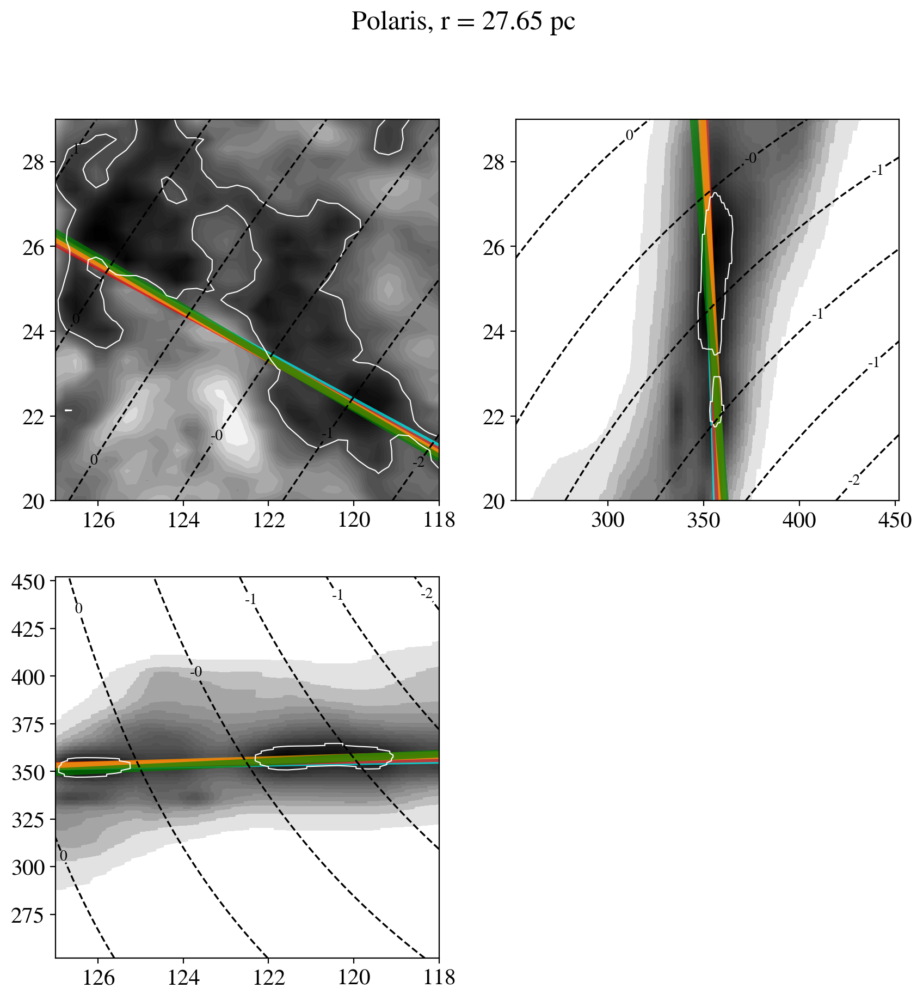

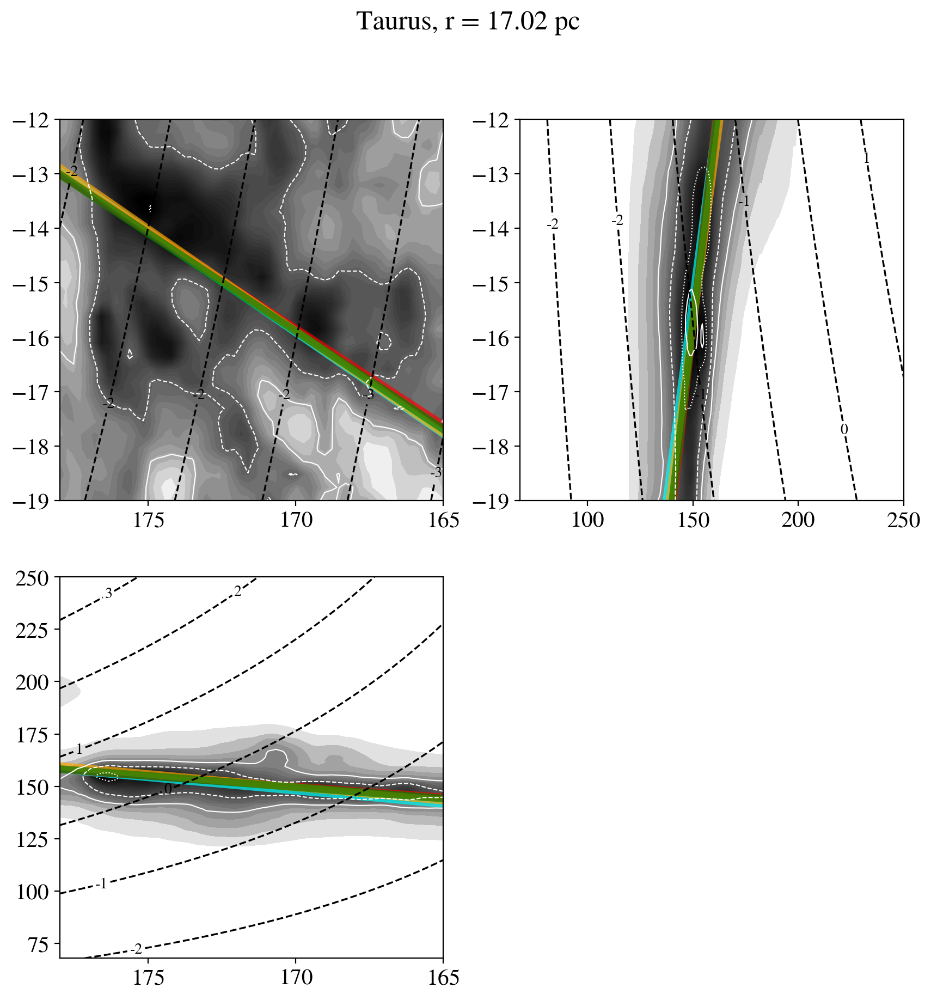

[(array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], d

In [72]:
[(
    
axs,
plot_spine(axs,dict_['spine'],scolor='cyan'),
    
[
plot_spine(axs,dict_['spine'],scolor=clr) 
    for d,clr in zip([3*r,2*r,r],['red','orange','green',])
    for dict_ in [ha(i,ednhfr_cm3,d)]
],
     
plt.show())
    
for i,r in zip(range(12) ,drs)
for dict_ in [ha(i,ednhfr_cm3,100)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],
                             names[i]+', r = '+str(np.around(r,2))+' pc',
                              _ ,b_parl=dict_['b_parl'])]

]

# fig 2

In [58]:
rho_radial_profiles

<function dust_3d_functions.rho_radial_profiles(i, source_array, drange='by r', cmapping='sane', plt_='new', color='black', lbl='by r')>

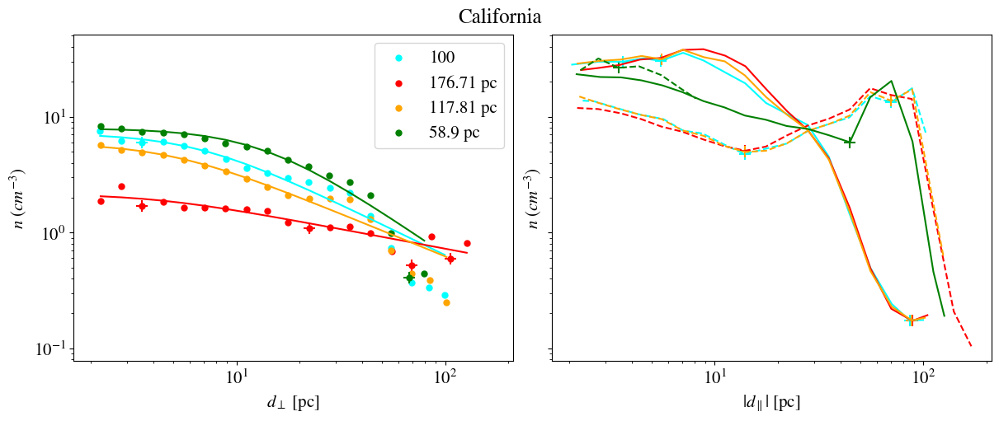

[(array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
         <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
        dtype=object),
  [(array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
           <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
          dtype=object),
    [2.15, 4.09, 0.17]),
   (array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
           <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
          dtype=object),
    [5.92, 4.77, 0.37]),
   (array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
           <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
          dtype=object),
    [7.94, 13.31, 0.62])],
  None)]

In [123]:
[(
# print('rho0:',fitpars[0],'r0:',fitpars[0],'alpha:',fitpars[0]),
ax,

[rho_radial_profiles(i,ednhfr_cm3, d,plt_=ax,color=clr,lbl=f'{round(d,2)} pc') 
 for d,clr in zip([3*r,2*r,r],['red','orange','green',])],
    
ax[0].legend(),
plt.show()
) for i,r in zip([0],drs[:1])
  for ax,fitpars in [rho_radial_profiles(i,ednhfr_cm3,100,color='cyan',lbl=100)]
]

In [125]:
names

0         California
1     Camelopardalis
2           Coalsack
3             Corona
4           Hercules
5              MonR2
6          Ophiuchus
7            Orion A
8            Orion B
9            Perseus
10           Polaris
11            Taurus
Name: Name, dtype: object

In [136]:
cmap_ = plt.cm.Spectral.resampled(30)

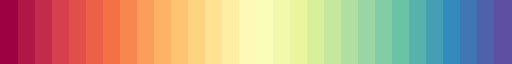

In [137]:
cmap_

In [131]:
cmap_(0)

(0.6196078431372549, 0.00392156862745098, 0.25882352941176473, 1.0)

In [135]:
len(np.arange(10,300,10))

29

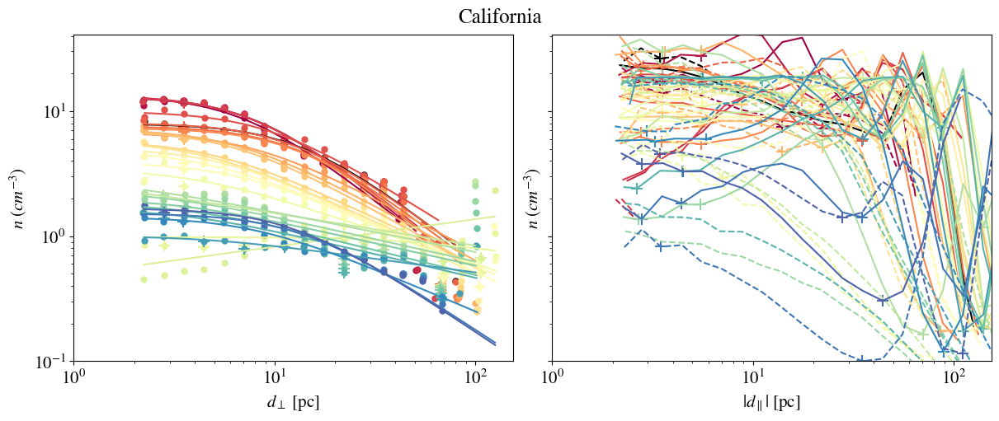

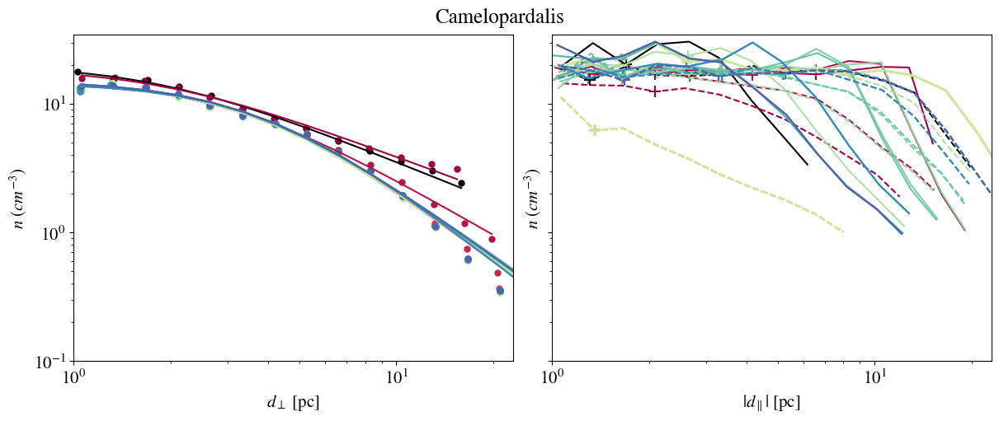

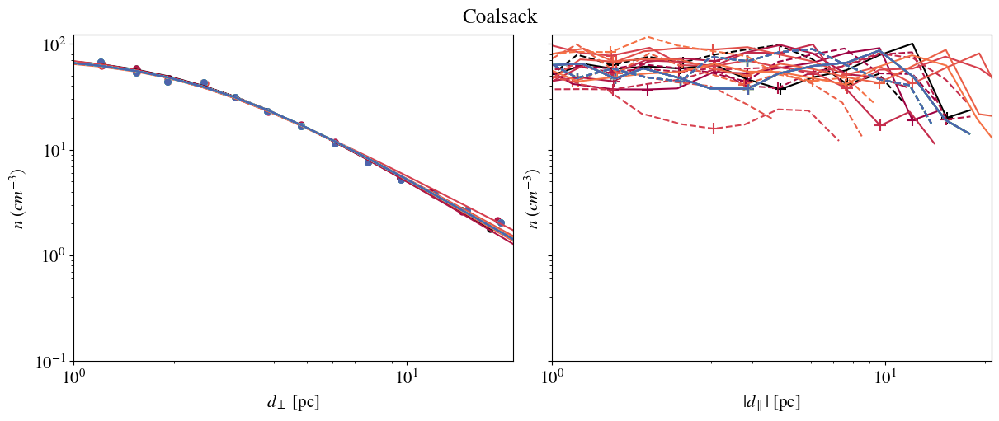

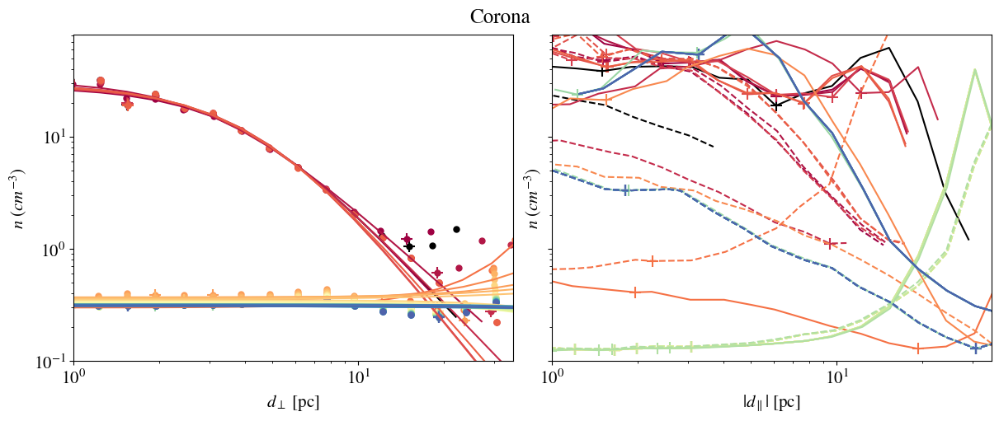

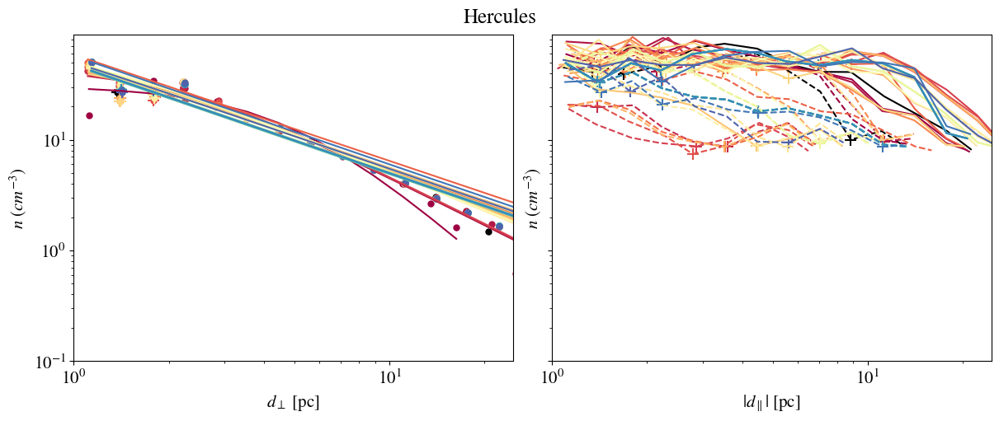

...

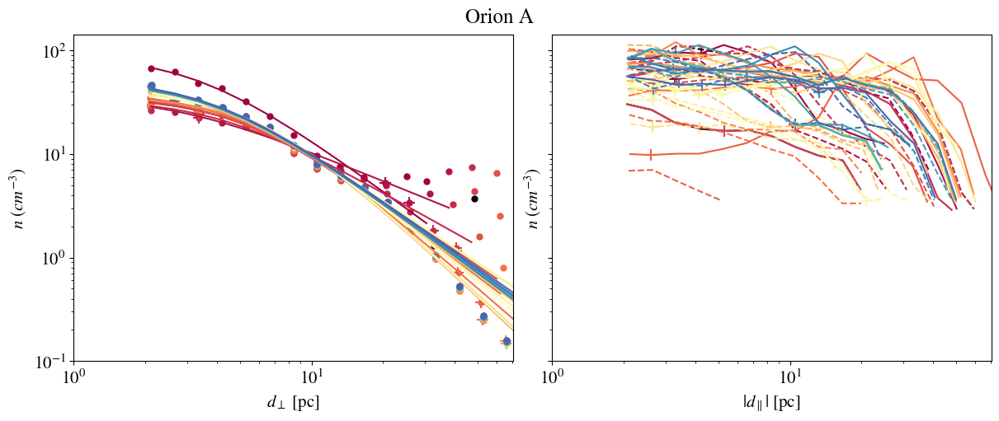

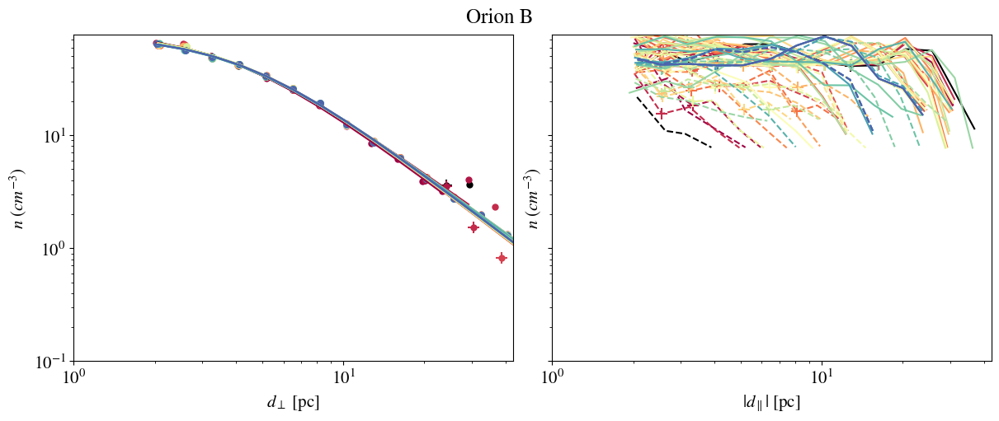

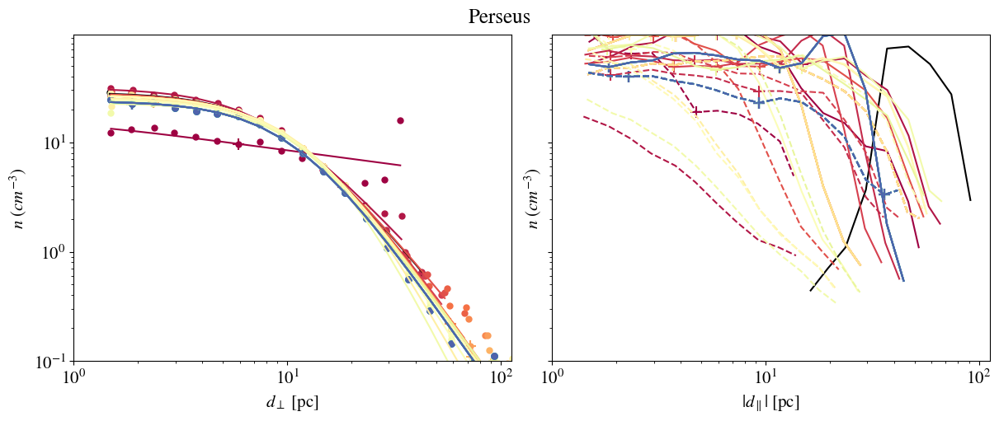

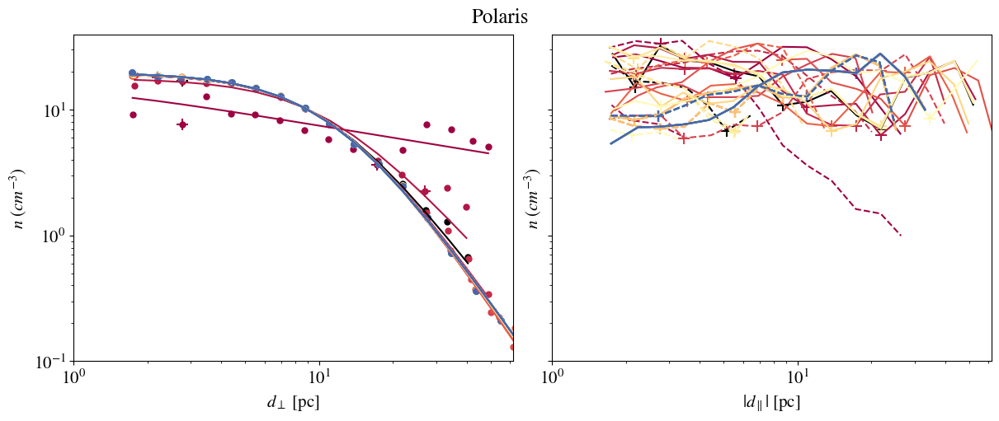

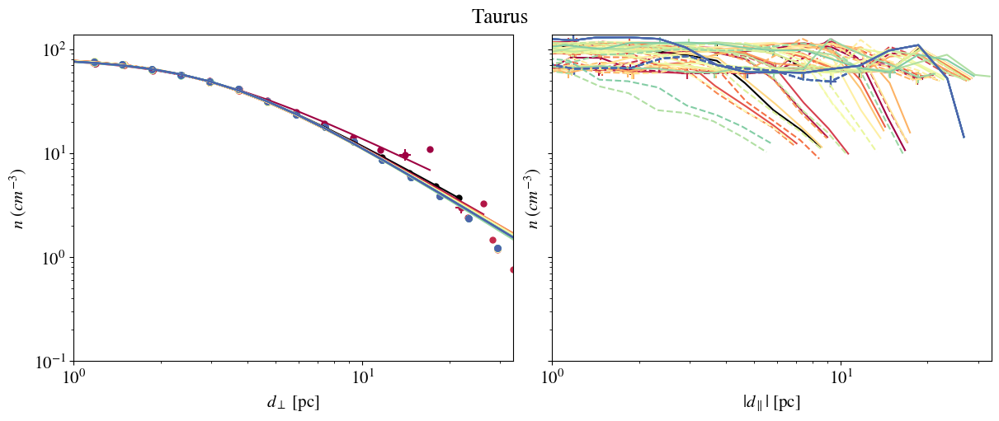

[(array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
         <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
        dtype=object),
  [(array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
           <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
          dtype=object),
    [13.45, 7.06, 0.64]),
   (array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
           <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
          dtype=object),
    [13.07, 8.54, 0.69]),
   (array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
           <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
          dtype=object),
    [13.38, 7.67, 0.63]),
   (array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
           <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm

In [139]:
[(
# print('rho0:',fitpars[0],'r0:',fitpars[0],'alpha:',fitpars[0]),
ax,

[rho_radial_profiles(i,ednhfr_cm3, d,plt_=ax,color=cmap_(j),lbl=f'{round(d,2)} pc') 
 for j,d in enumerate(np.arange(10,300,10))],
    
# ax[0].legend(),
plt.show()
) for i,r in zip(range(12) ,drs)
  for ax,fitpars in [rho_radial_profiles(i,ednhfr_cm3,'by r',color='black',lbl='r')]
]

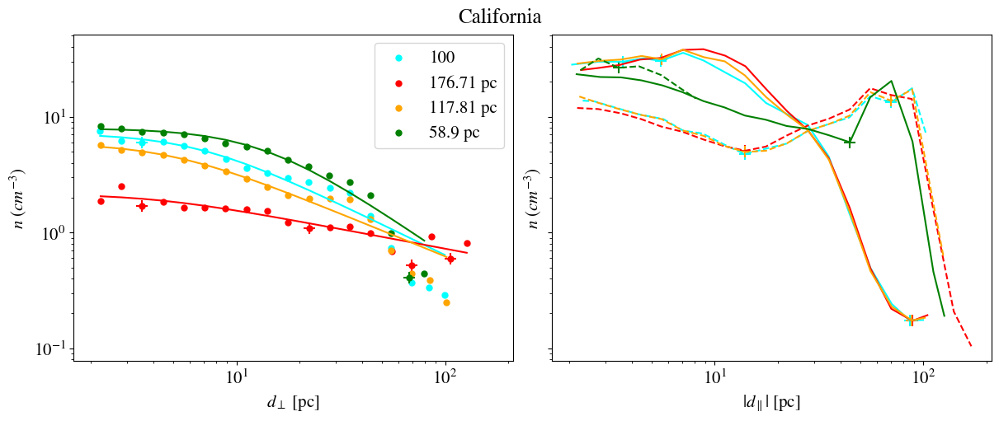

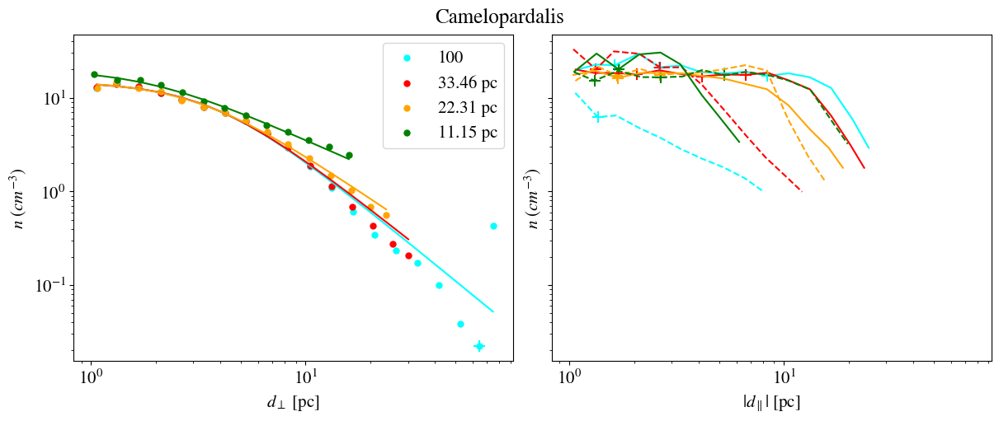

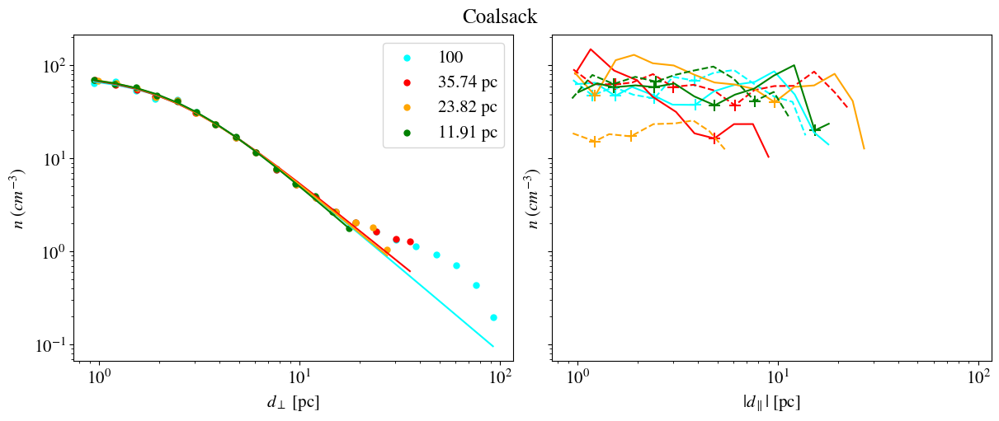

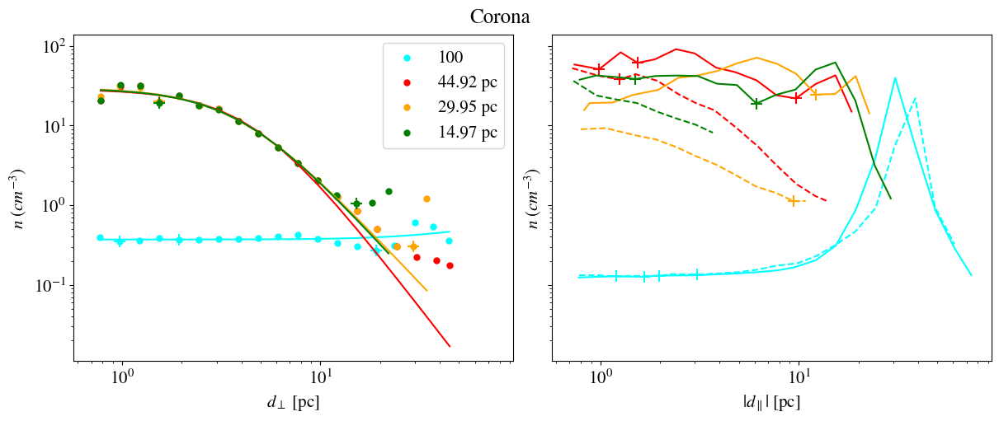

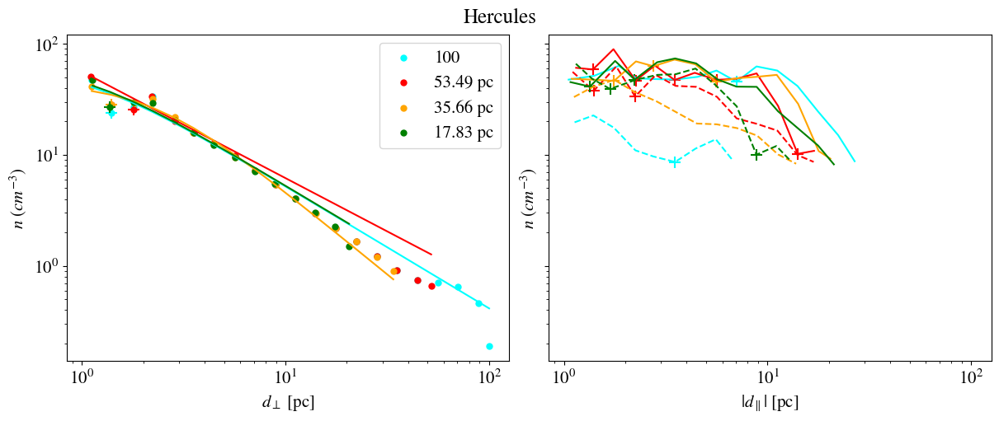

...

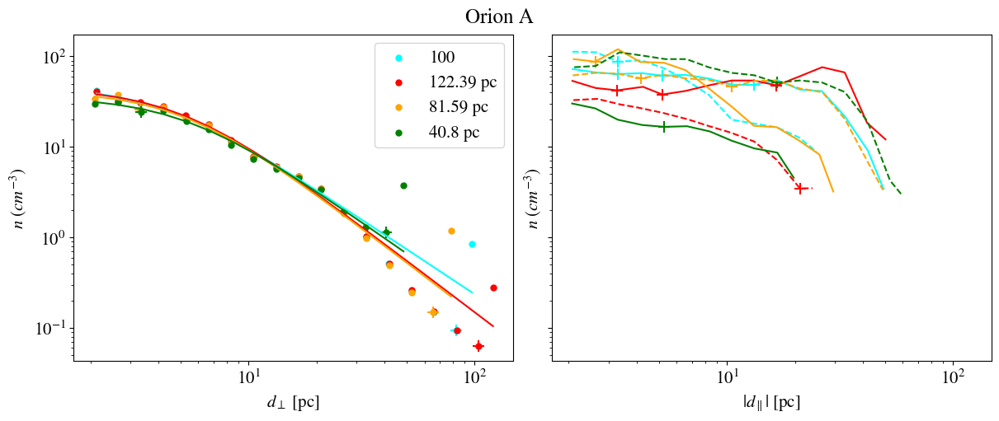

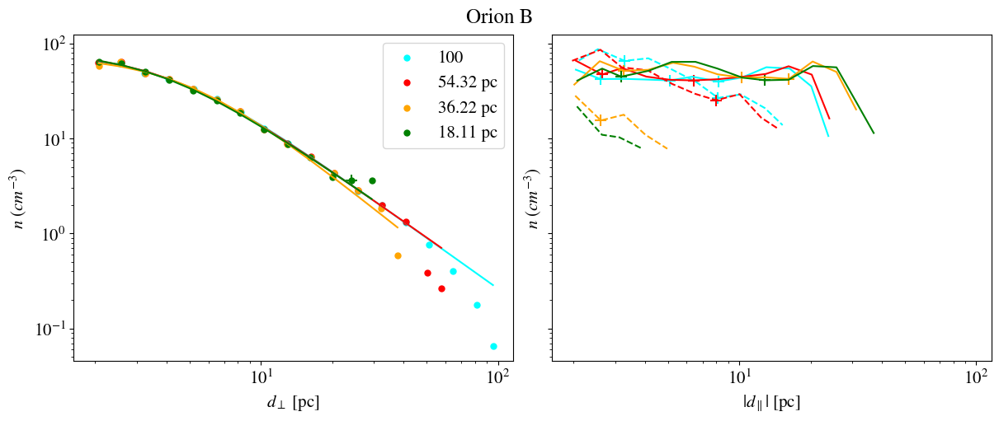

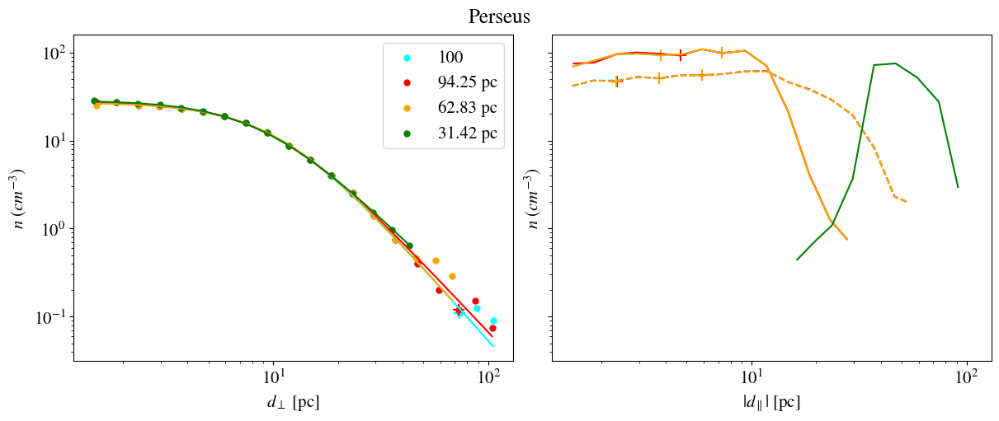

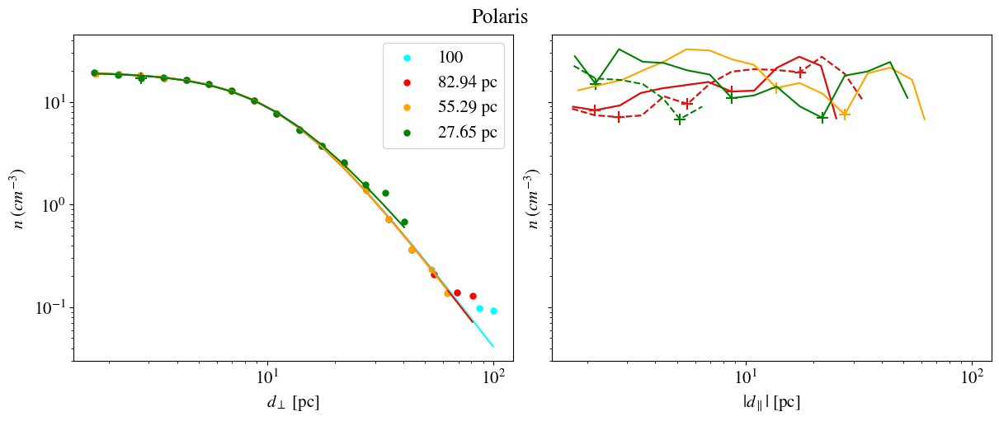

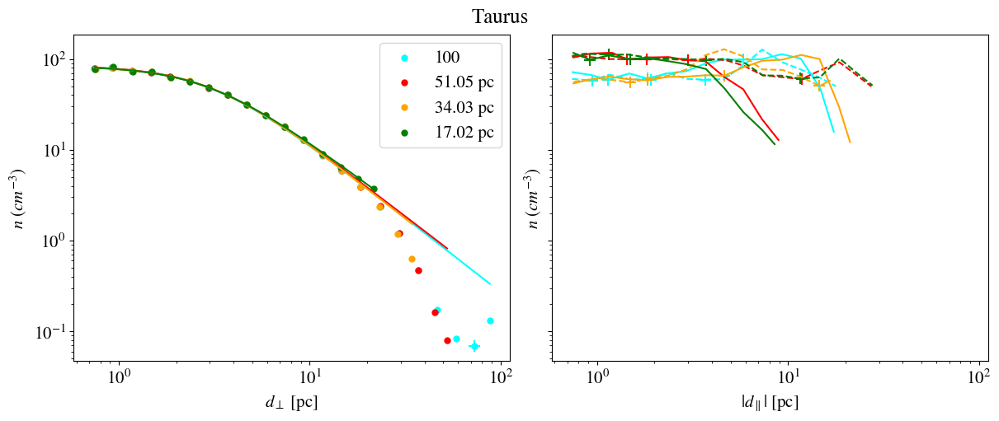

[(array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
         <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
        dtype=object),
  [(array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
           <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
          dtype=object),
    [2.15, 4.09, 0.17]),
   (array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
           <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
          dtype=object),
    [5.92, 4.77, 0.37]),
   (array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
           <Axes: xlabel='$|d_\\parallel|\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>],
          dtype=object),
    [7.94, 13.31, 0.62])],
  None),
 (array([<Axes: xlabel='$d_\\perp\\ [\\mathrm{pc}]$', ylabel='$n\\ (cm^{-3})$'>,
         <Axes: xlabel='$|d_\\parallel|\\ [\\ma

In [124]:
[(
# print('rho0:',fitpars[0],'r0:',fitpars[0],'alpha:',fitpars[0]),
ax,

[rho_radial_profiles(i,ednhfr_cm3, d,plt_=ax,color=clr,lbl=f'{round(d,2)} pc') 
 for d,clr in zip([3*r,2*r,r],['red','orange','green',])],
    
ax[0].legend(),
plt.show()
) for i,r in zip(range(12) ,drs)
  for ax,fitpars in [rho_radial_profiles(i,ednhfr_cm3,100,color='cyan',lbl=100)]
]

# fig 3

In [91]:
get_cloud_info

<function dust_3d_functions.get_cloud_info(i, source_array, drange='by r')>

In [93]:
len(table1)

12

2.068992


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


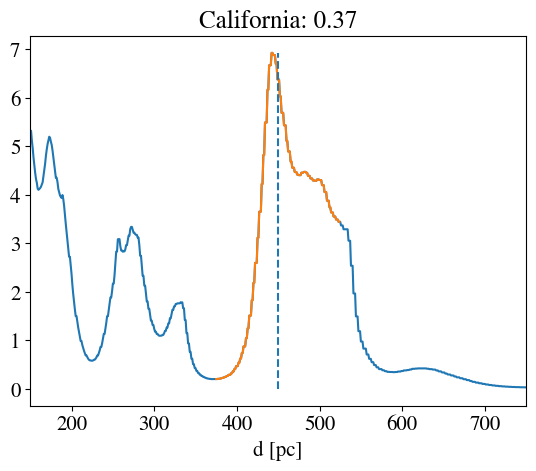

2.550017


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


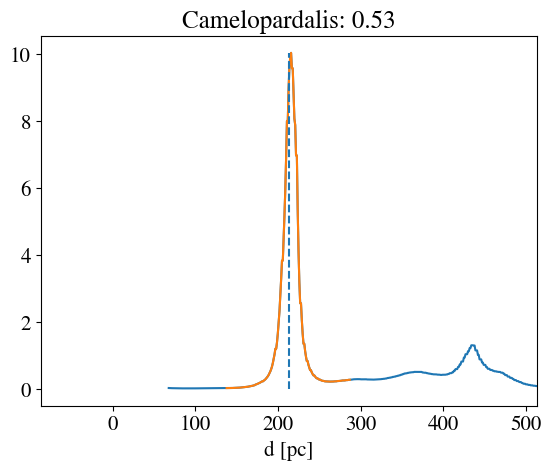

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


6.160024


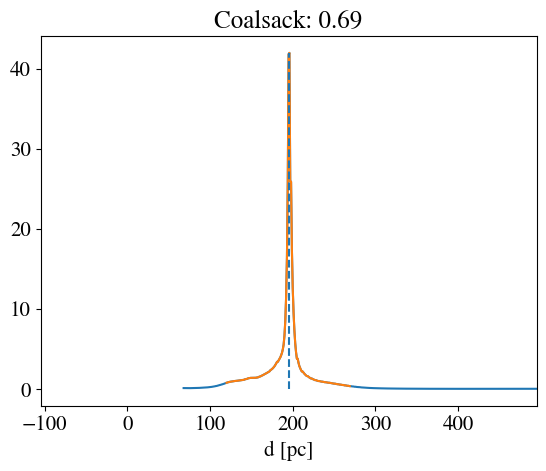

2.3219721


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


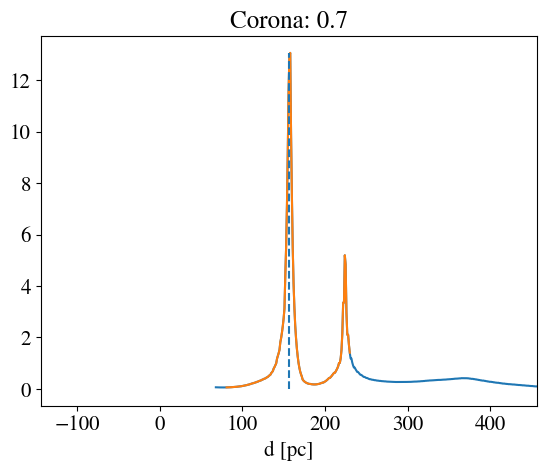

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


3.415196


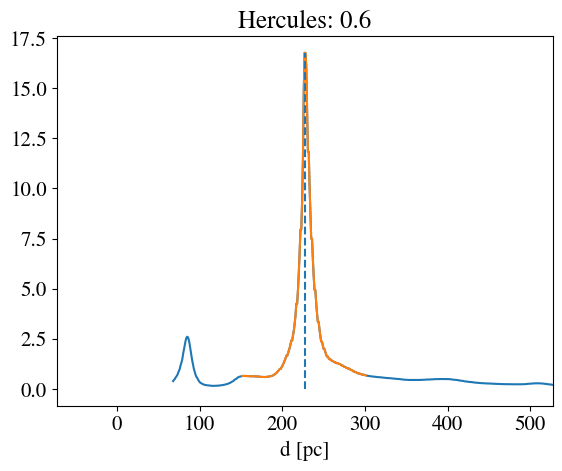

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


1.9660653


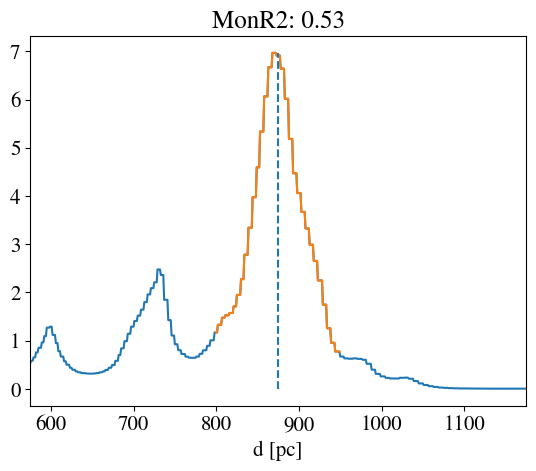

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


15.739131


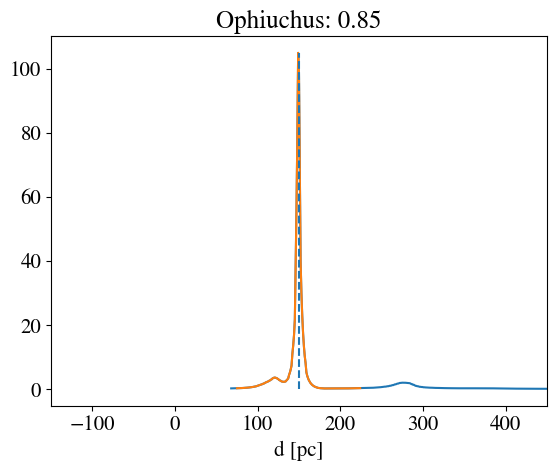

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


5.020713


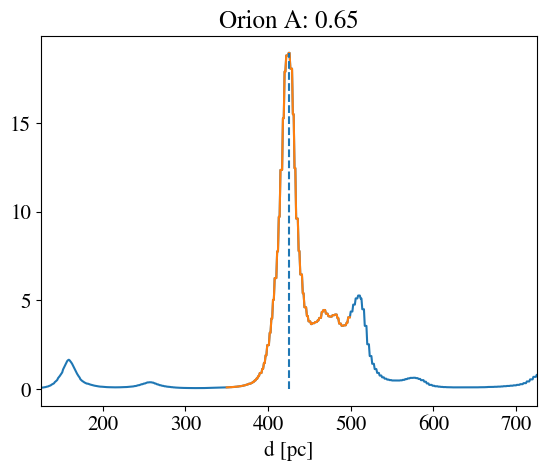

6.8076887


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


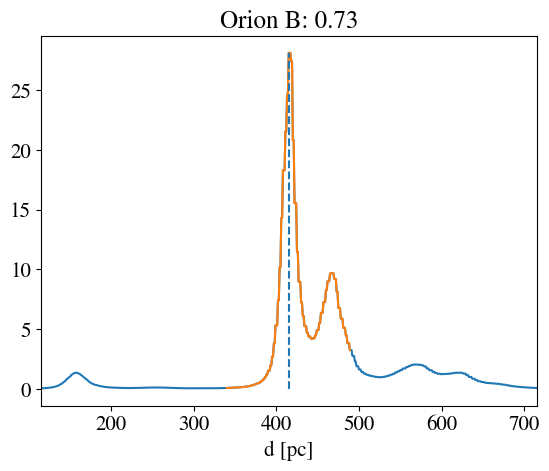

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


3.9641197


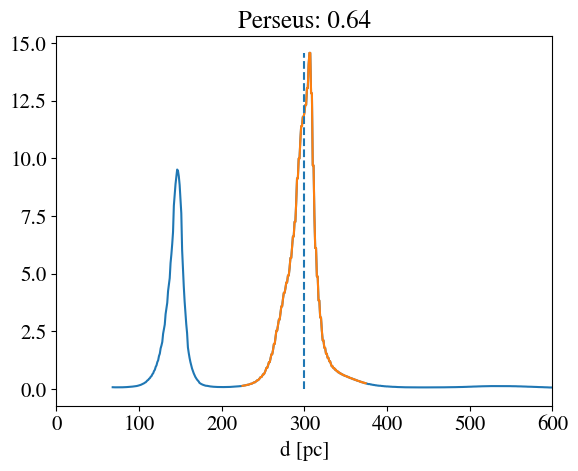

2.772025


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


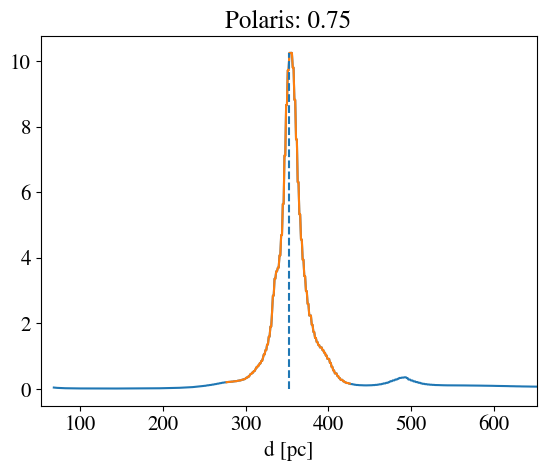

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_13486/3342570680.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


9.144344


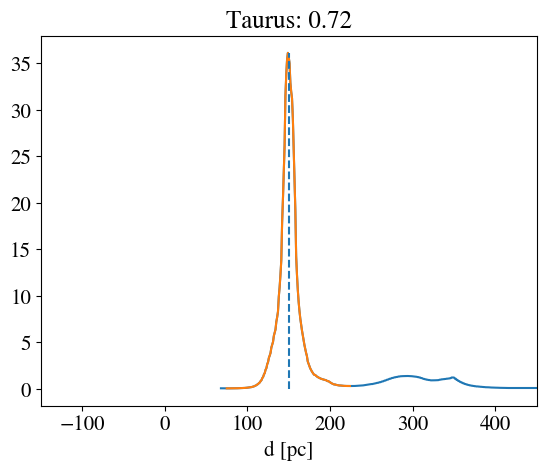

[([<matplotlib.lines.Line2D at 0x78a762ed0>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  (150.0, 750.0),
  Text(0.5, 1.0, 'California: 0.37'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x78b02a090>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  (-87.0, 513.0),
  Text(0.5, 1.0, 'Camelopardalis: 0.53'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x78b09a890>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  (-105.0, 495.0),
  Text(0.5, 1.0, 'Coalsack: 0.69'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x78b0faad0>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  (-144.0, 456.0),
  Text(0.5, 1.0, 'Corona: 0.7'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x78b178490>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  (-73.0, 527.0),
  Text(0.5, 1.0, 'Hercules: 0.6'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x78b183010>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  (575.0, 1175.0),
  Text(0.5, 1.0, 'MonR2: 0.53'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x78b

In [117]:
[(
plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
plt.plot(np.arange(cube.shape[0])+coords[4],np.nanmean(cube,axis=(1,2))),

plt.vlines(ds[i],0,np.nanmax(np.nanmean(cube,axis=(1,2))),linestyle='--'),

plt.xlabel('d [pc]'),
plt.xlim(ds[i]+np.array([-1,1])*300),
plt.title(names[i]+': '+str(round(np.nansum(cube)/np.nansum(cubel),2))),
# plt.plot(np.nanmean(cube,axis=(1,2)))

print(np.nanstd(np.nanmean(cube,axis=(1,2)))),

plt.show()
) 

for i in range(12)#in_edenhfr #range(26) 
for cube,coords in [get_cloud_info(i,ednhfr_cm3,75)]
for cubel,coordsl in [get_cloud_info(i,ednhfr_cm3,'full')] 
]

# fig 5

TypeError: 'int' object is not subscriptable

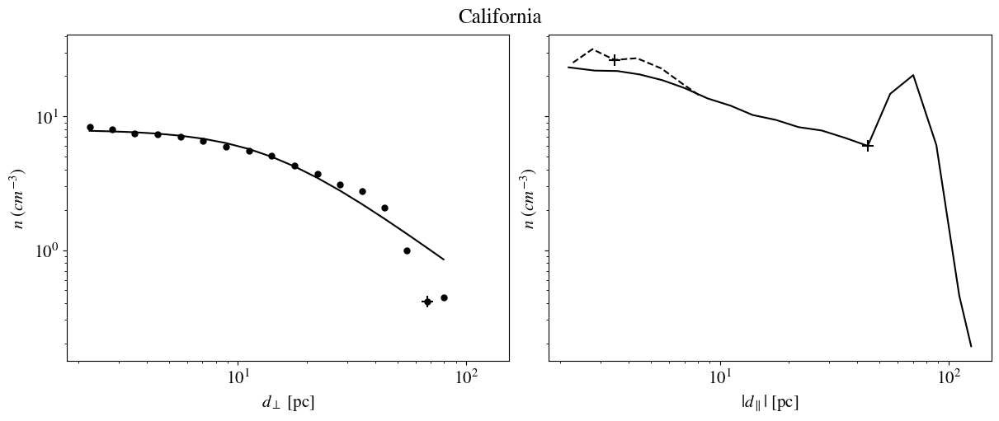

In [126]:
[(
ax,

[rho_radial_profiles(i,d,plt_=ax,color=cmap_(j*2),lbl=f'{d} pc') 
 for j,d in enumerate([10,30,50,70,100,150,300,])],
    
print(),

ax.legend(),
plt.show()
) for i in range(18) for ax,err_sum in [rho_radial_profiles(i,ednhfr_cm3)]
]

In [ ]:
#RESUME HERE - i am trying to track down the above error and then hopefully it will give me the plot of the 
#radial profile as i smoothly vary the dsitance ranges -> the place where there is a break is where the cloud starts / ends 

In [ ]:
og_if_clouds = [11,4,15,12,13,1,10,]

In [ ]:
lewis_rs = [19.7,3.2,13.1,23.0,21.6,35.,36.7] #order the same as if clouds

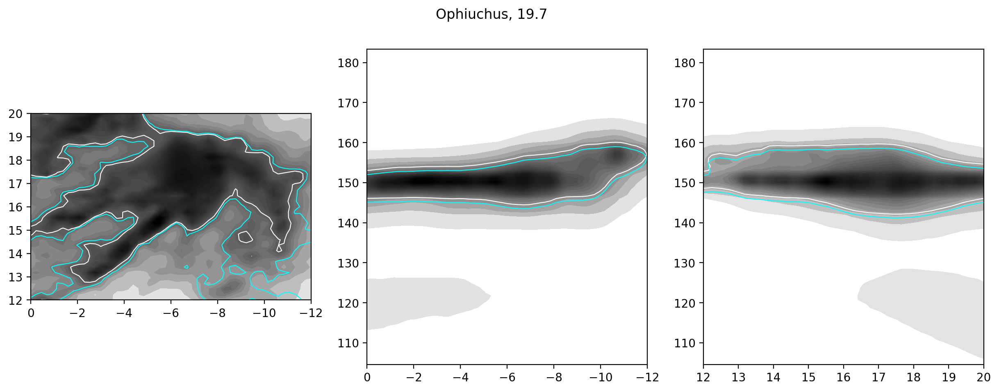

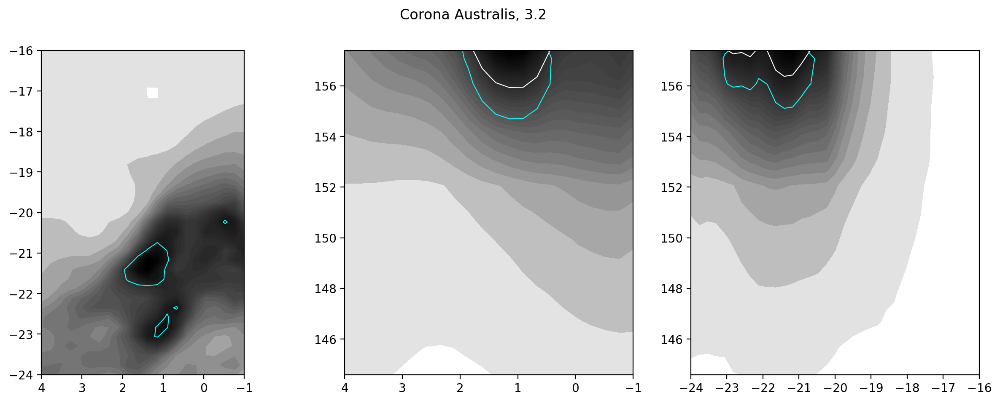

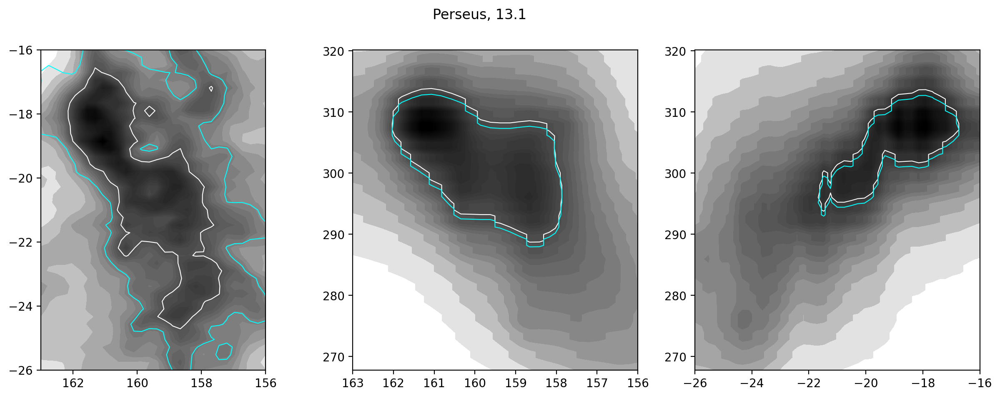

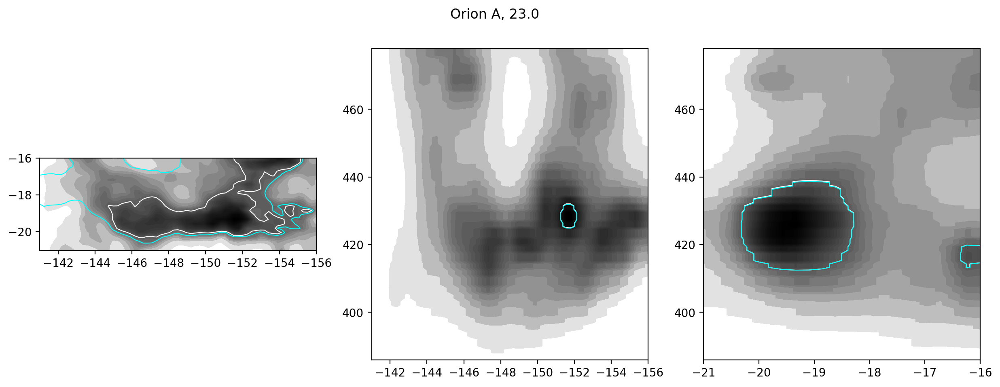

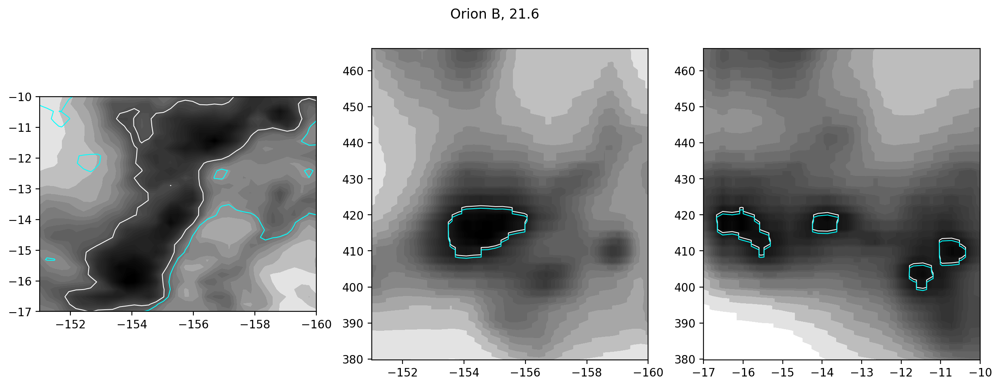

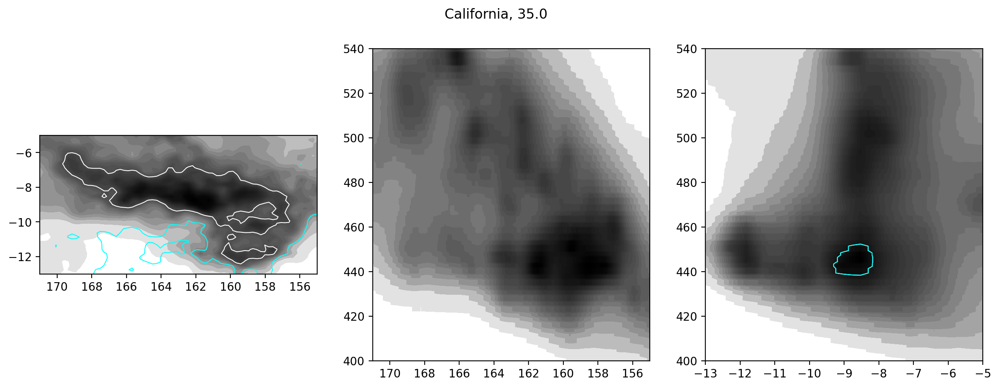

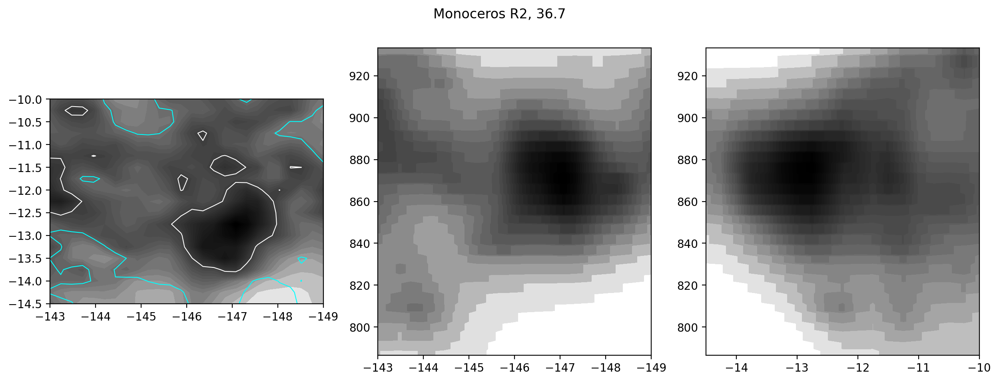

[(array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None)]

In [ ]:
[(
    
axs,
    
[
plot_contour(axs,dict_['dust_cube'],dict_['coords'],[1],'cyan')

for dict_ in [ha(i,'full')]
],
     
plt.show())
    
for i,r in zip(og_if_clouds ,lewis_rs)
for dict_ in [ha(i,2*r,0.5)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],names[i]+', '+str(r))]

]

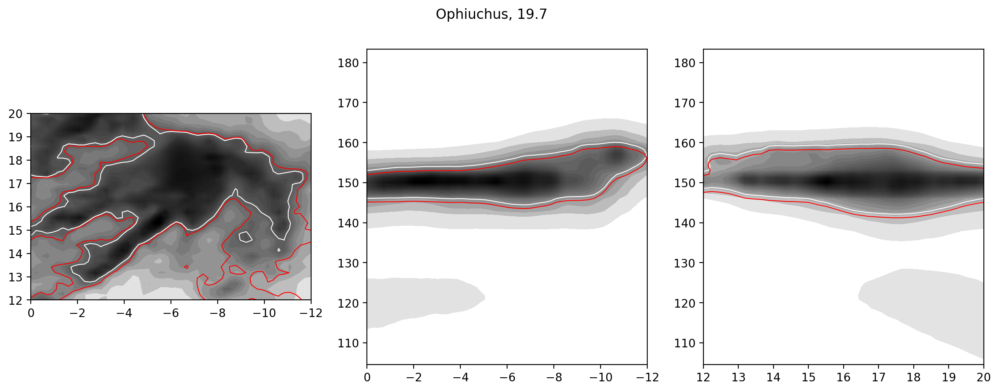

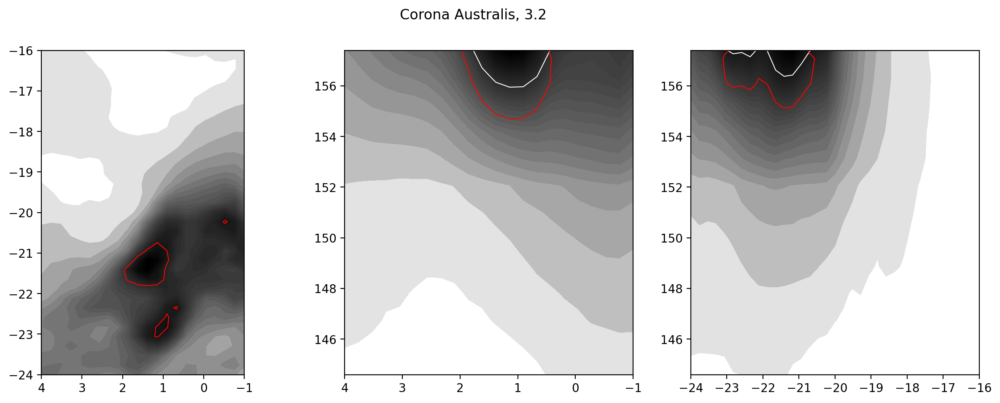

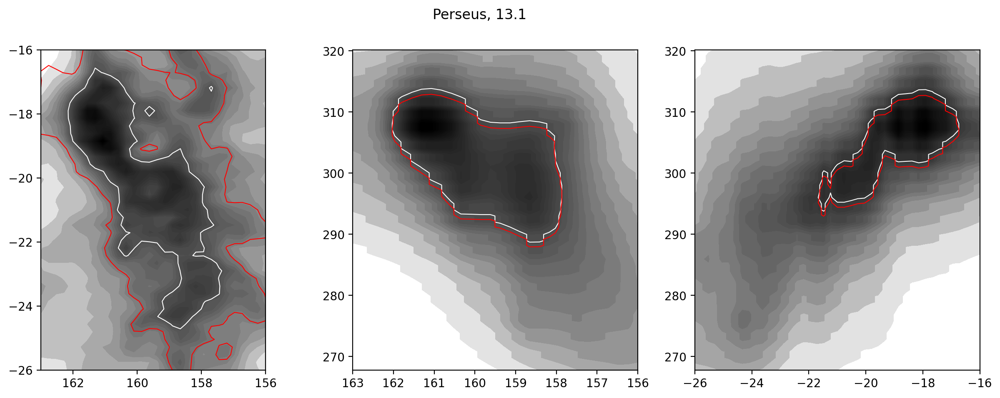

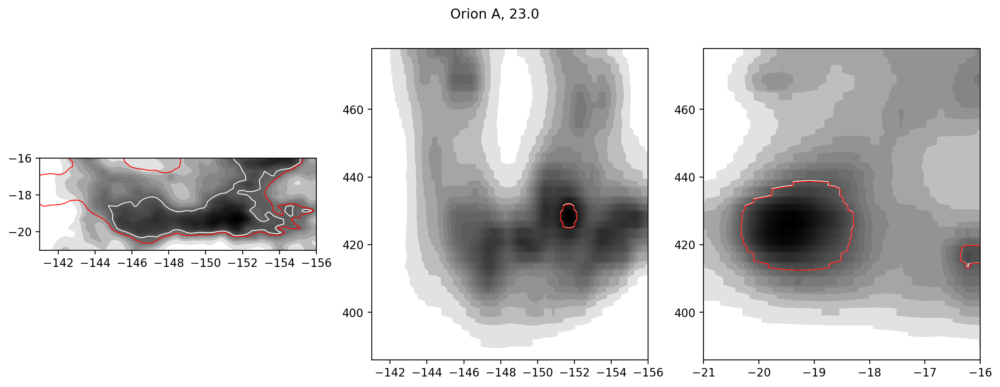

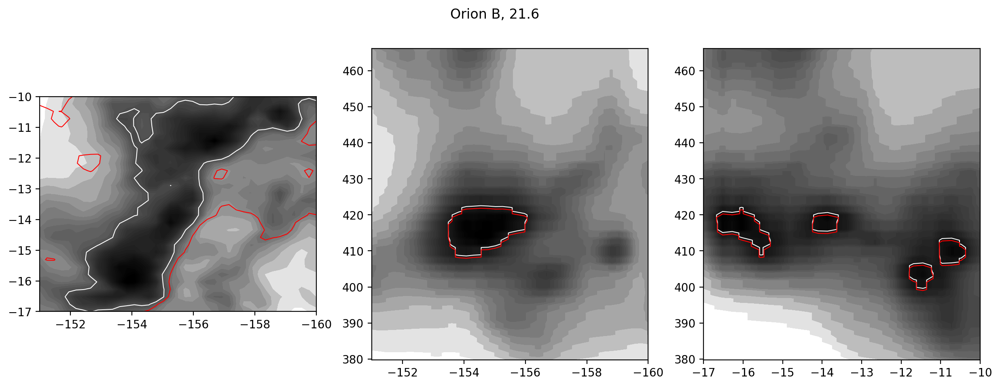

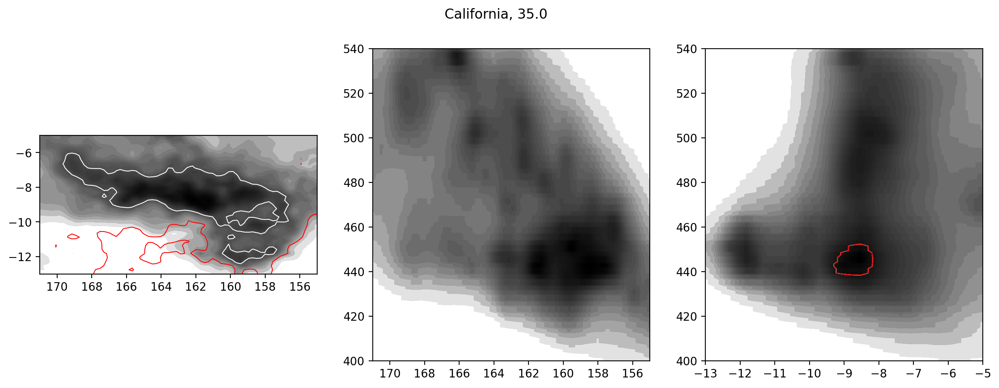

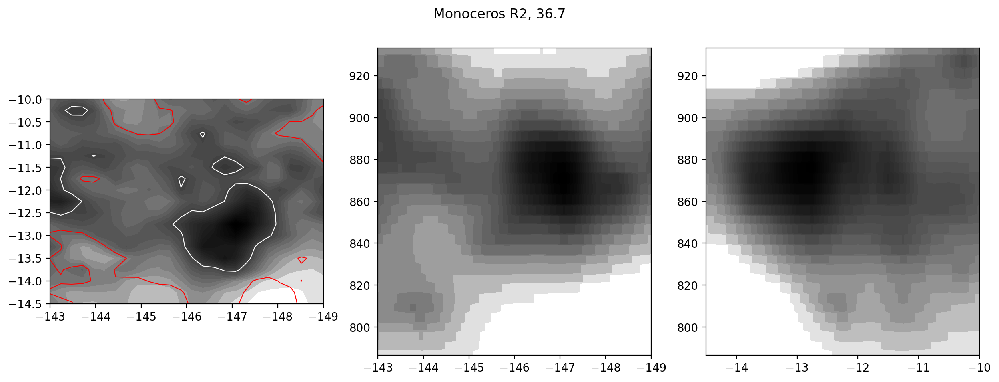

[(array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None)]

In [ ]:
[(
    
axs,
    
[
plot_contour(axs,dict_['dust_cube'],dict_['coords'],[1],'red')

for dict_ in [ha(i,'full')]
],
     
plt.show())
    
for i,r in zip(og_if_clouds ,lewis_rs)
for dict_ in [ha(i,2*r,1)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],names[i]+', '+str(r))]

]

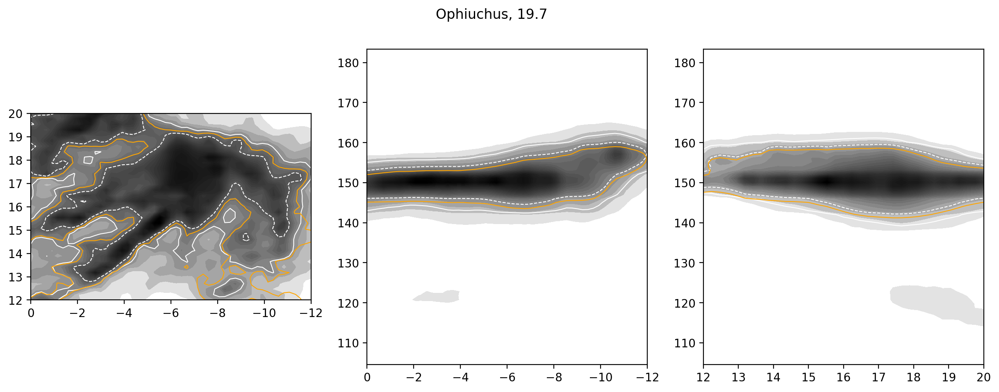

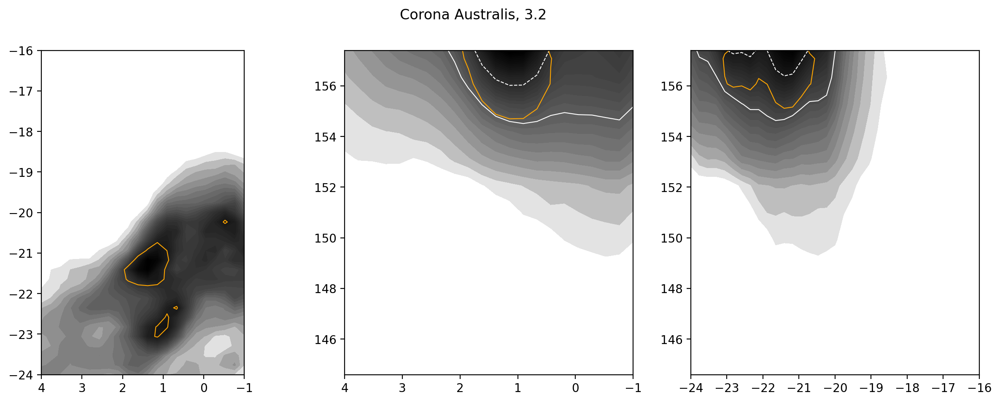

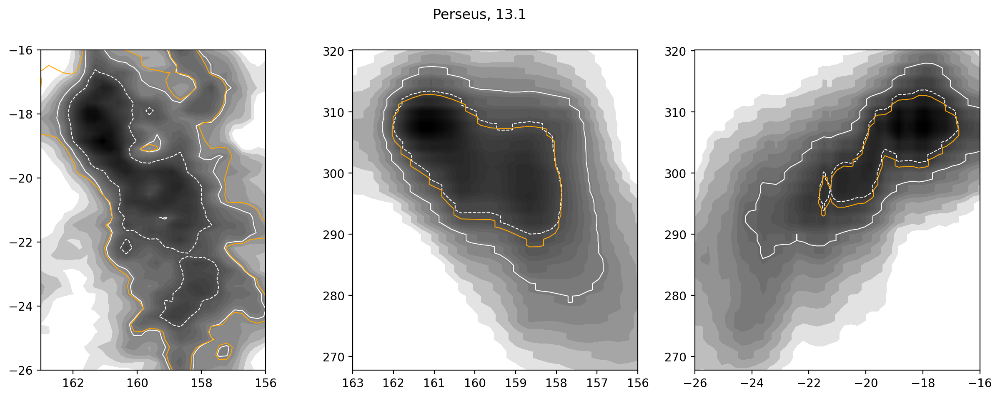

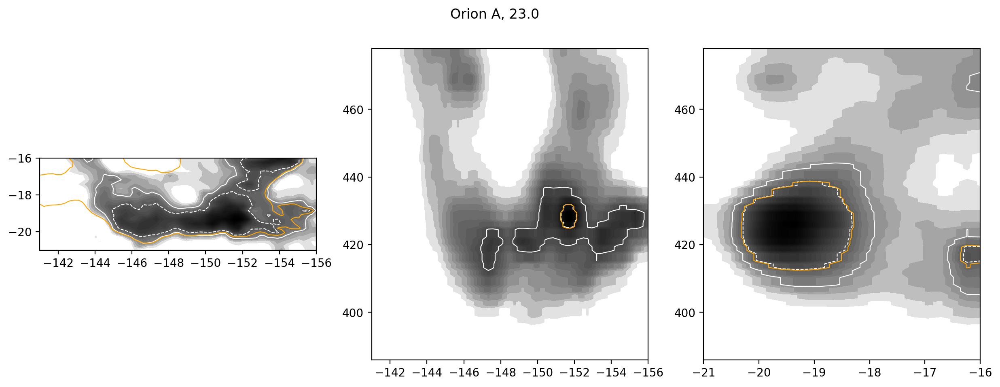

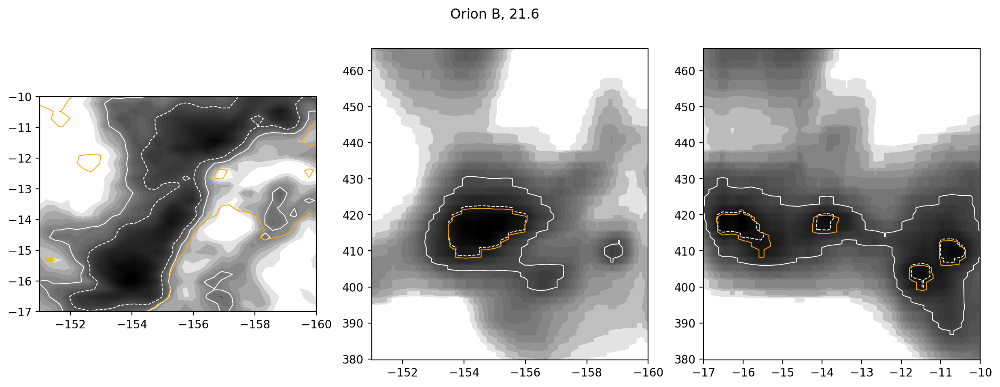

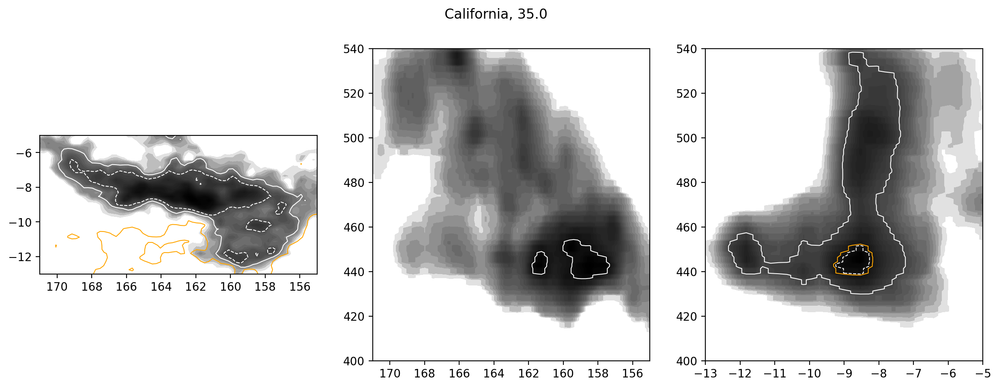

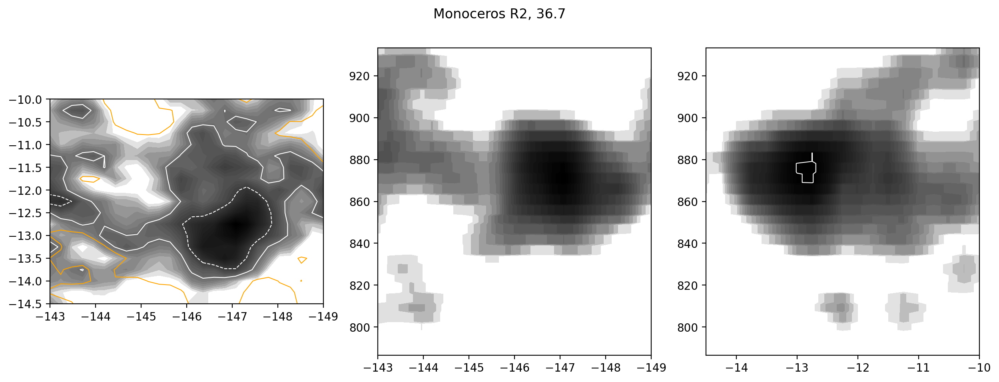

[(array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), [None], None)]

In [ ]:
[(
    
axs,
    
[
plot_contour(axs,dict_['dust_cube'],dict_['coords'],[1],'orange')

for dict_ in [ha(i,'full')]
],
     
plt.show())
    
for i,r in zip(og_if_clouds ,lewis_rs)
for dict_ in [ha(i,2*r,5)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],names[i]+', '+str(r))]

]

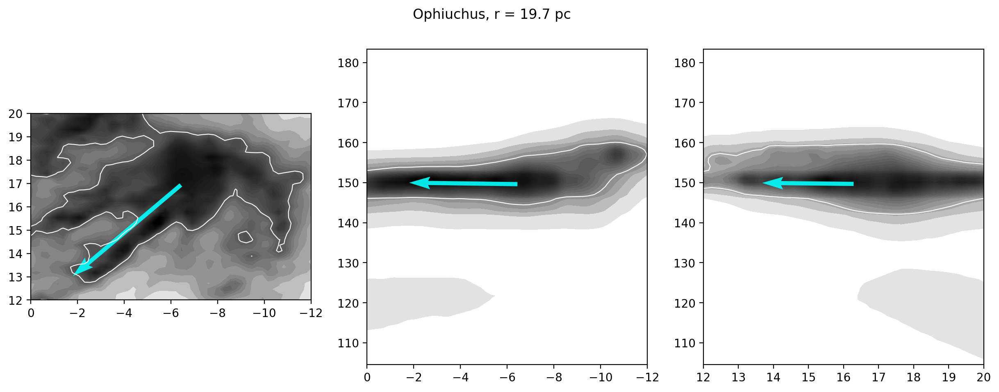

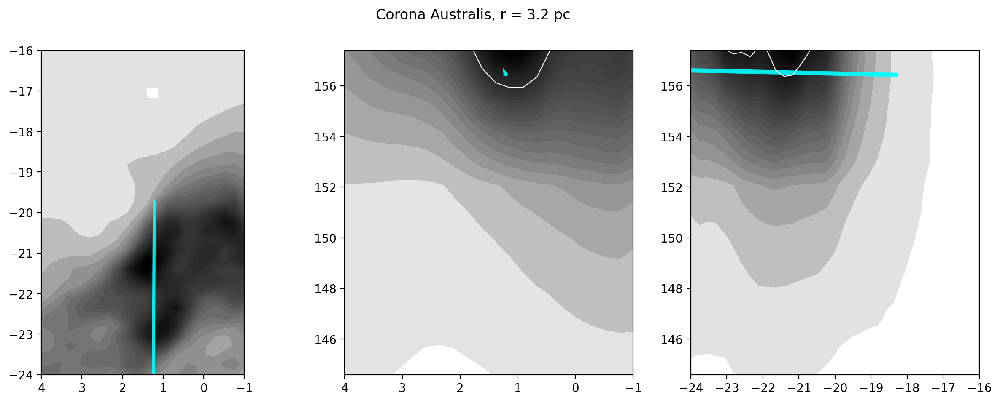

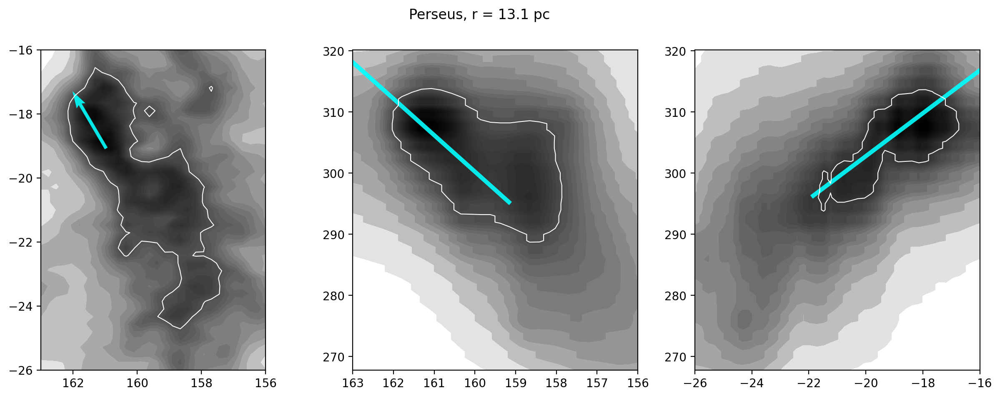

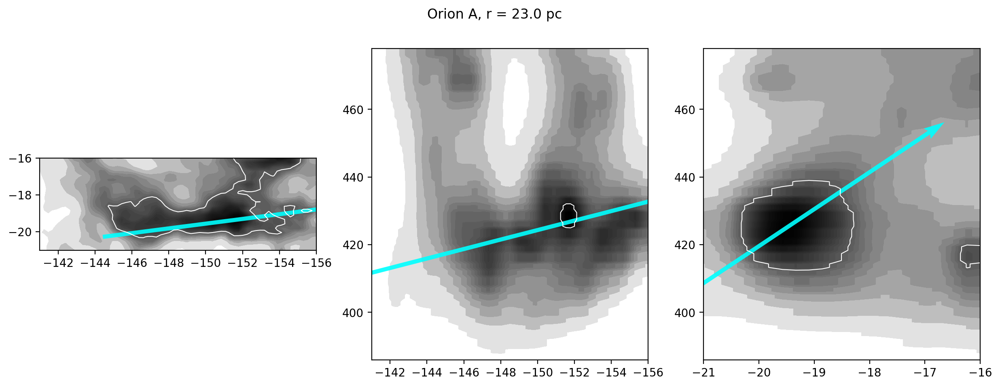

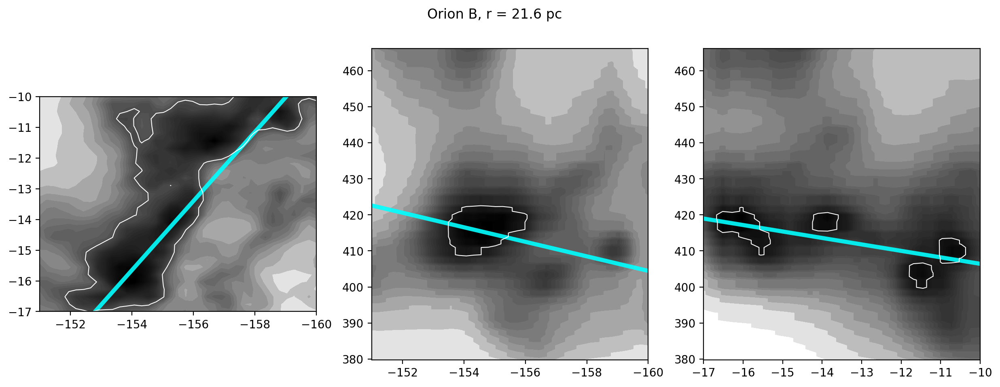

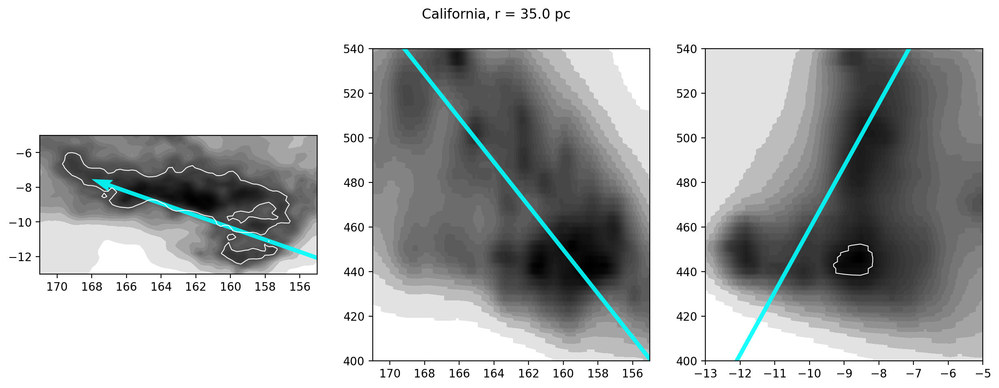

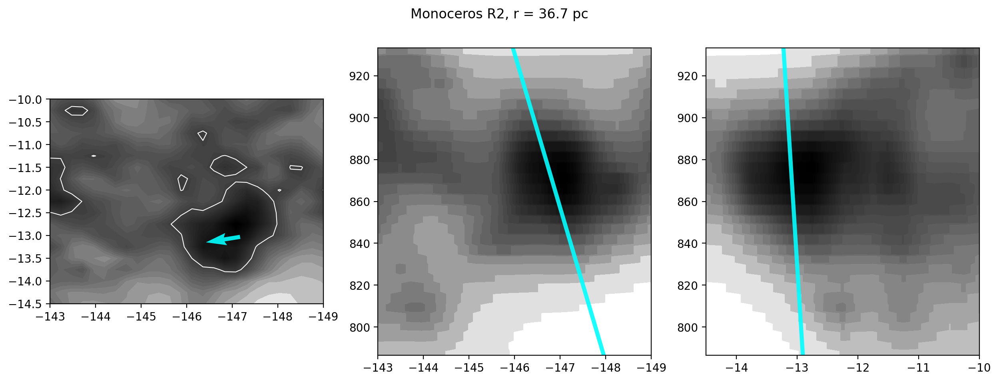

[(array([<Axes: >, <Axes: >, <Axes: >], dtype=object), None, None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), None, None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), None, None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), None, None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), None, None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), None, None),
 (array([<Axes: >, <Axes: >, <Axes: >], dtype=object), None, None)]

In [ ]:
[(
    
axs,
plot_spine(axs,dict_['spine'],scolor='cyan'),
    
# [
# plot_spine(axs,dict_['spine'],scolor=clr) 
#     for d,clr in zip([r,2*r,3*r],['green','orange','red'])
#     for dict_ in [ha(i,d)]
# ],
     
plt.show())
    
for i,r in zip(og_if_clouds ,lewis_rs)
for dict_ in [ha(i,2*r)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],names[i]+', r = '+str(r)+' pc')]

]

In [ ]:
#

rho0 142.37 r0 2.44 alpha 1.07
rho0 141.61 r0 2.51 alpha 1.1
rho0 147.18 r0 2.65 alpha 1.19
rho0 210.46 r0 1.72 alpha 0.98


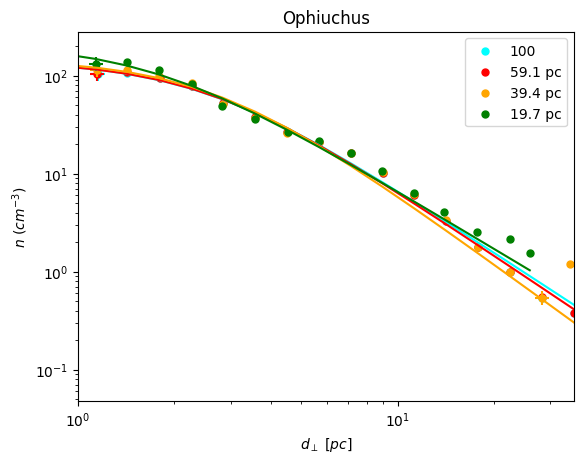

rho0 0.71 r0 3.37 alpha 0.27
rho0 9.58 r0 8.2 alpha 1.98
rho0 19.14 r0 2.65 alpha 1.08
rho0 14.99 r0 2.34 alpha 0.92


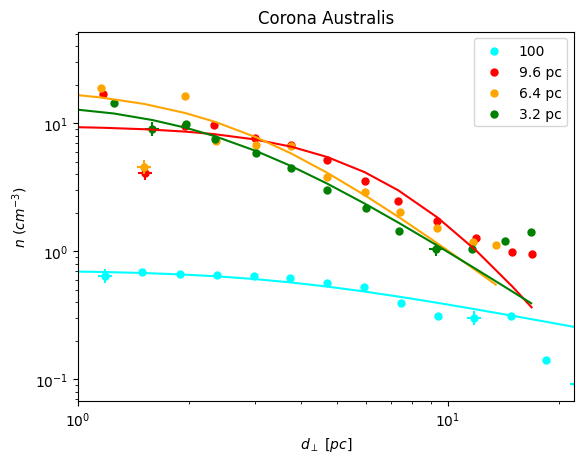

rho0 37.26 r0 8.73 alpha 1.32
rho0 37.01 r0 8.88 alpha 1.34
rho0 37.07 r0 8.3 alpha 1.23
rho0 39.73 r0 6.61 alpha 1.02


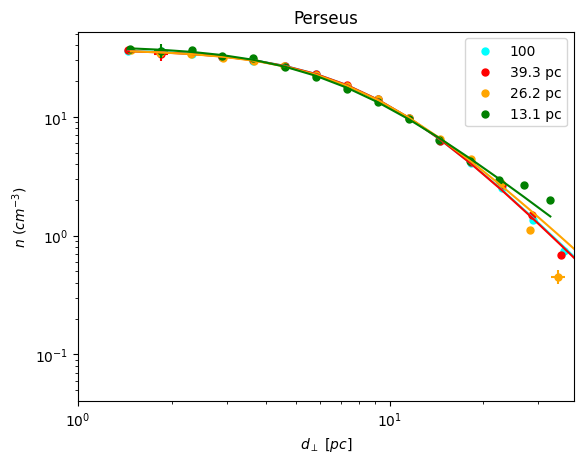

rho0 29.22 r0 5.93 alpha 0.97
rho0 27.06 r0 5.69 alpha 0.87
rho0 23.69 r0 6.01 alpha 0.83
rho0 20.09 r0 6.83 alpha 0.8


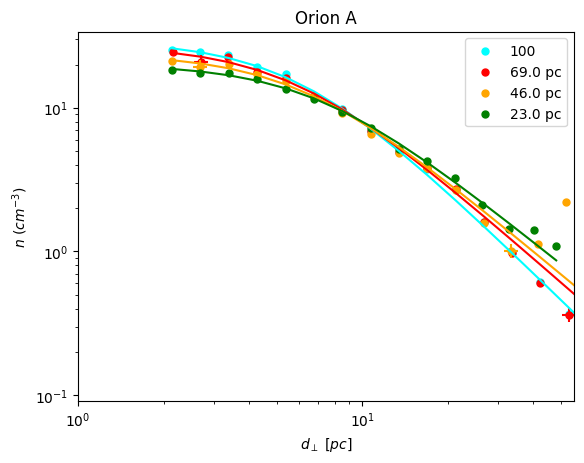

rho0 40.36 r0 5.9 alpha 0.84
rho0 40.3 r0 6.08 alpha 0.86
rho0 37.66 r0 6.42 alpha 0.87
rho0 39.93 r0 4.53 alpha 0.69


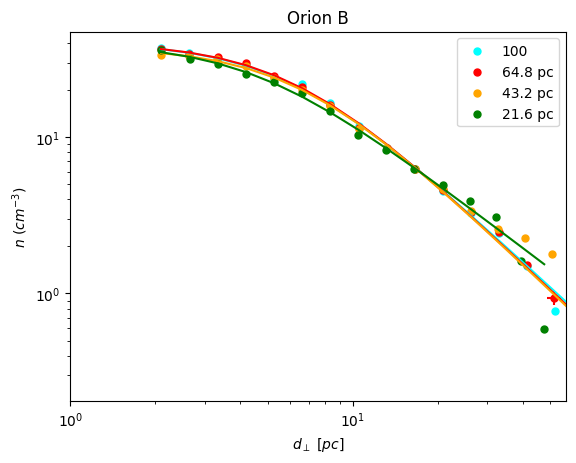

rho0 7.48 r0 17.16 alpha 1.02
rho0 7.03 r0 17.74 alpha 1.03
rho0 9.8 r0 15.5 alpha 0.9
rho0 10.16 r0 11.22 alpha 0.62


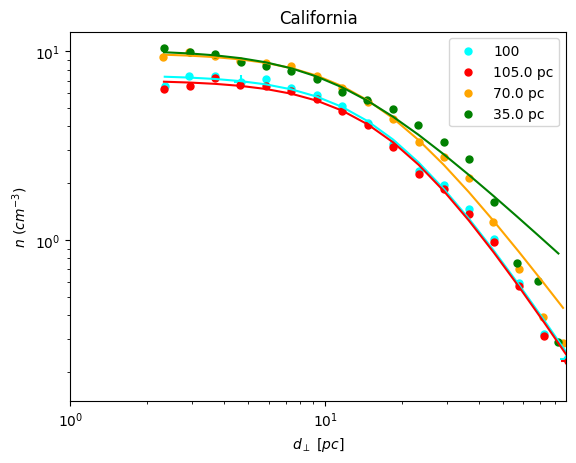

rho0 0.91 r0 9.32 alpha -0.13
rho0 0.77 r0 11.31 alpha -0.13
rho0 29.78 r0 0.01 alpha 0.16
rho0 22.68 r0 5.28 alpha 0.52


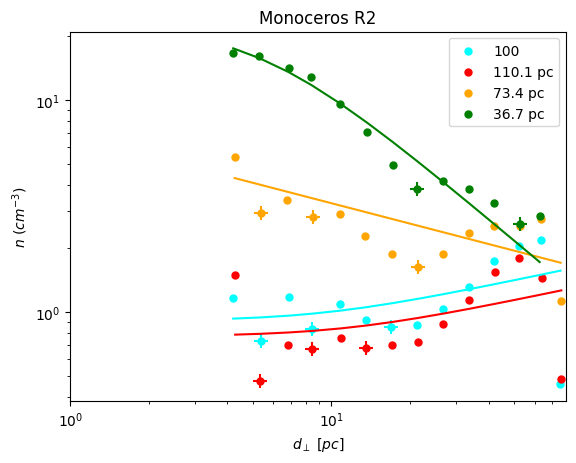

[(<Axes: title={'center': 'Ophiuchus'}, xlabel='$d_\\perp\\ [pc]$', ylabel='$n\\ (cm^{-3})$'>,
  [(<Axes: title={'center': 'Ophiuchus'}, xlabel='$d_\\perp\\ [pc]$', ylabel='$n\\ (cm^{-3})$'>,
    [141.61, 2.51, 1.1]),
   (<Axes: title={'center': 'Ophiuchus'}, xlabel='$d_\\perp\\ [pc]$', ylabel='$n\\ (cm^{-3})$'>,
    [147.18, 2.65, 1.19]),
   (<Axes: title={'center': 'Ophiuchus'}, xlabel='$d_\\perp\\ [pc]$', ylabel='$n\\ (cm^{-3})$'>,
    [210.46, 1.72, 0.98])],
  None),
 (<Axes: title={'center': 'Corona Australis'}, xlabel='$d_\\perp\\ [pc]$', ylabel='$n\\ (cm^{-3})$'>,
  [(<Axes: title={'center': 'Corona Australis'}, xlabel='$d_\\perp\\ [pc]$', ylabel='$n\\ (cm^{-3})$'>,
    [9.58, 8.2, 1.98]),
   (<Axes: title={'center': 'Corona Australis'}, xlabel='$d_\\perp\\ [pc]$', ylabel='$n\\ (cm^{-3})$'>,
    [19.14, 2.65, 1.08]),
   (<Axes: title={'center': 'Corona Australis'}, xlabel='$d_\\perp\\ [pc]$', ylabel='$n\\ (cm^{-3})$'>,
    [14.99, 2.34, 0.92])],
  None),
 (<Axes: title={'center'

In [ ]:
[(
# print('rho0:',fitpars[0],'r0:',fitpars[0],'alpha:',fitpars[0]),
ax,

[rho_radial_profiles(i,d,plt_=ax,color=clr,lbl=f'{round(d,2)} pc') 
 for d,clr in zip([3*r,2*r,r],['red','orange','green',])],
    
ax.legend(),
plt.show()
) for i,r in zip(og_if_clouds ,lewis_rs) for ax,fitpars in [rho_radial_profiles(i,100,color='cyan',lbl=100)]
]

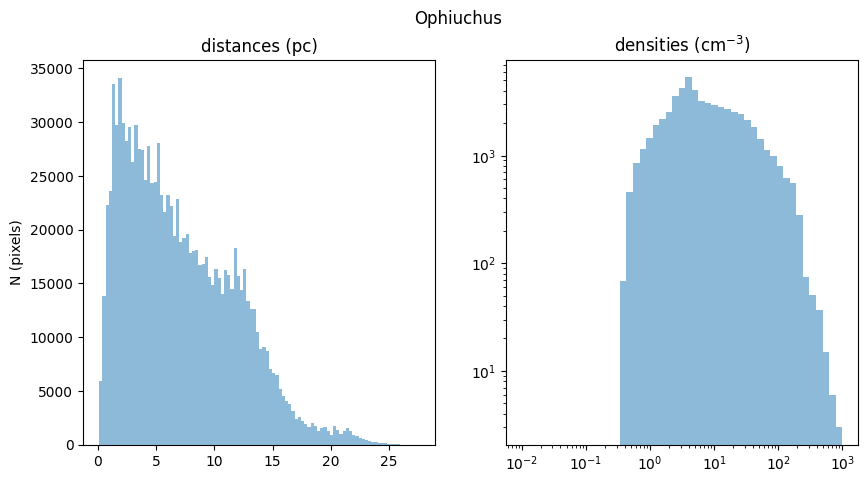

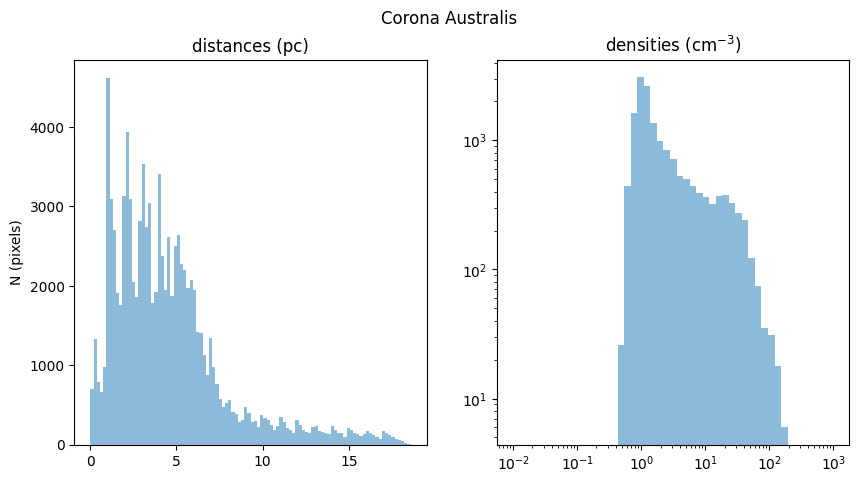

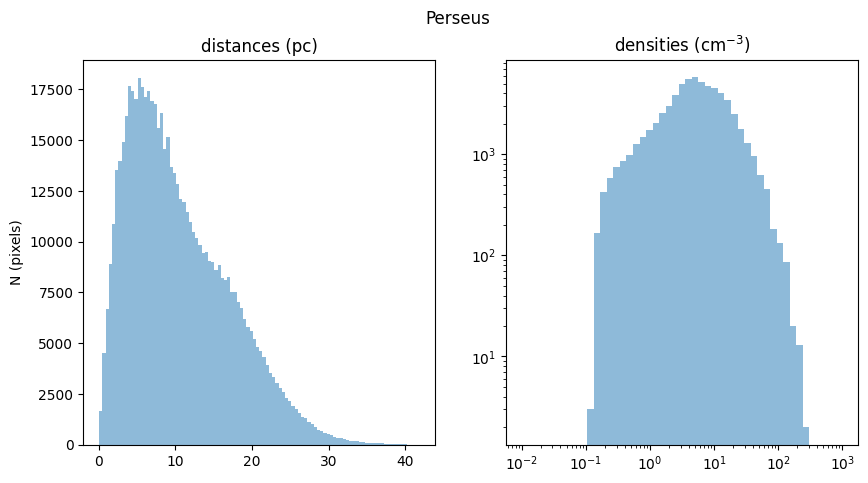

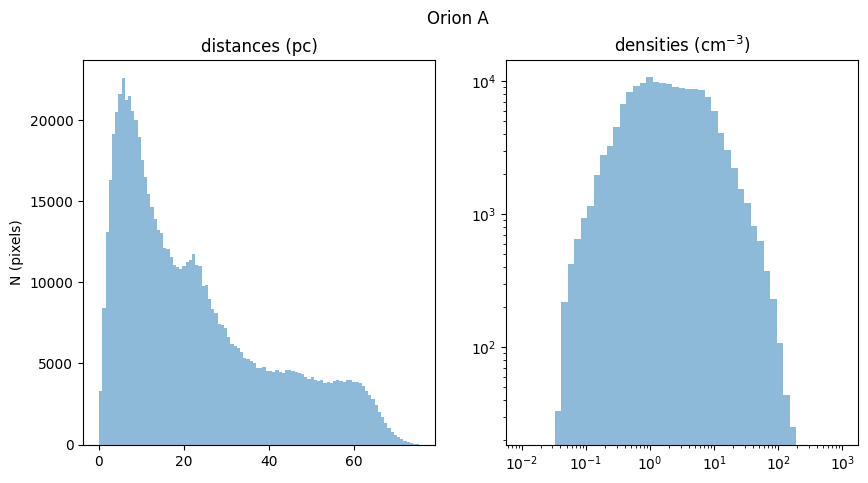

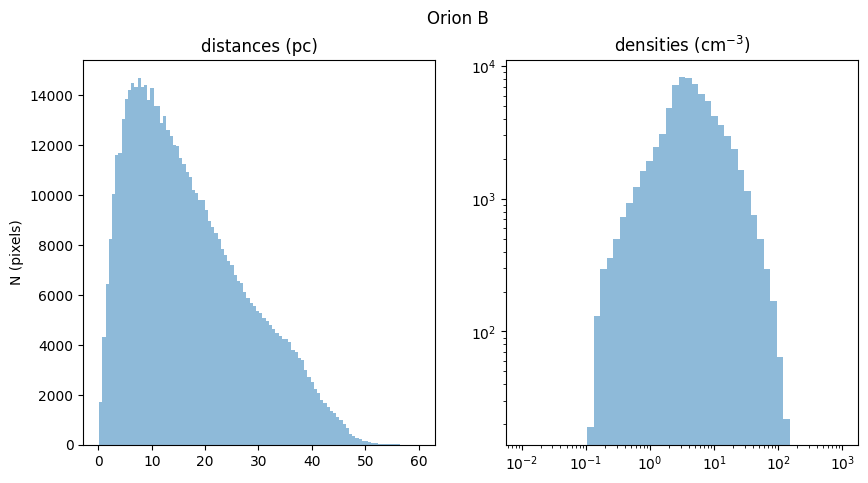

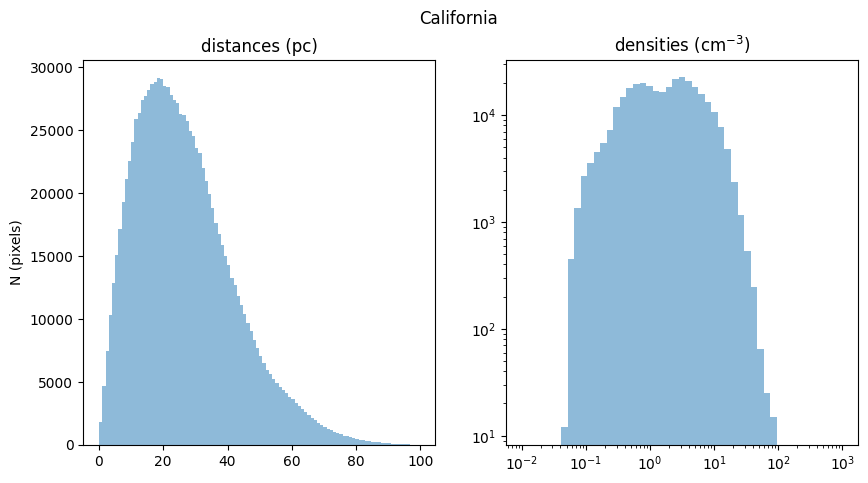

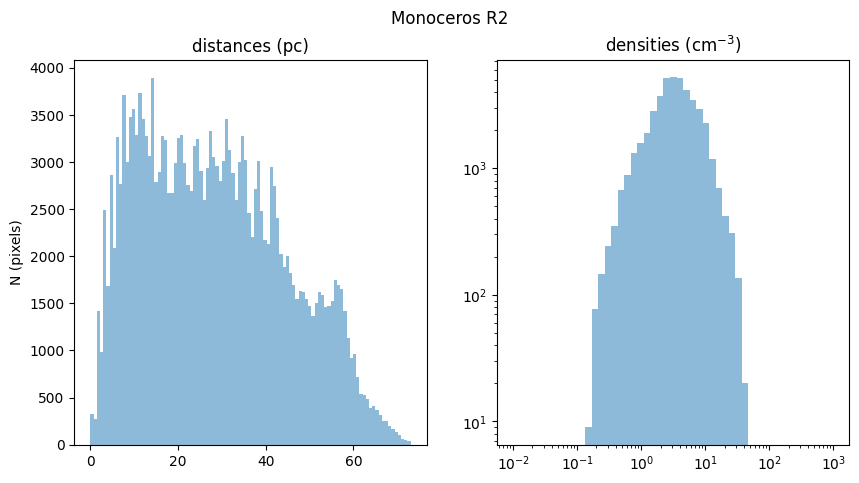

[None, None, None, None, None, None, None]

In [ ]:
[histogram(i,) for i,r in zip(og_if_clouds,lewis_rs)]

In [ ]:
#use the density profile along the spine to decide when to cut off / cap the spine
#plot ^ within a cylinder of a few pc
#and also bin along bparallel
#

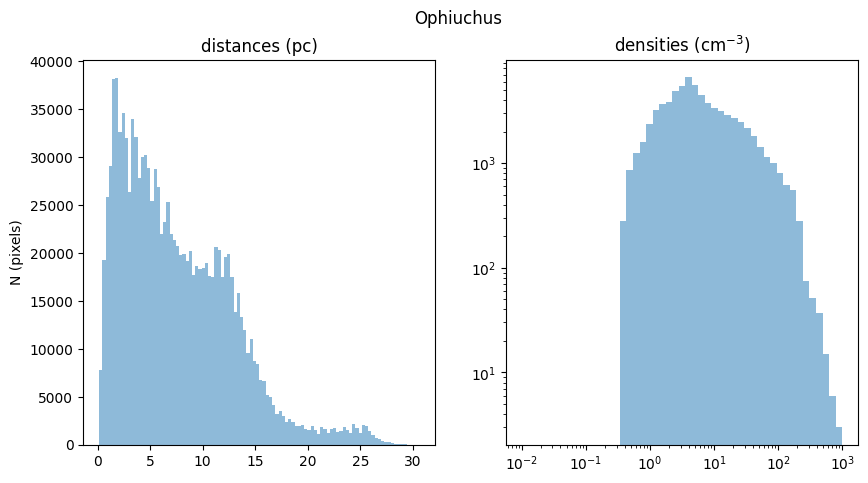

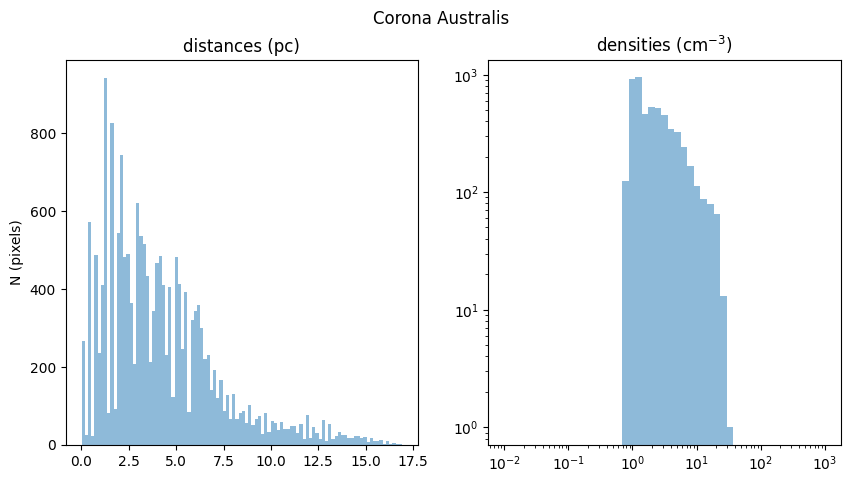

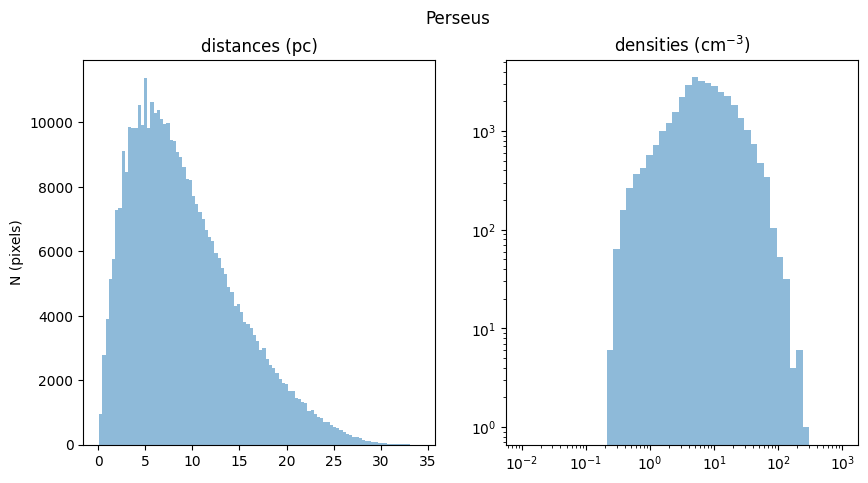

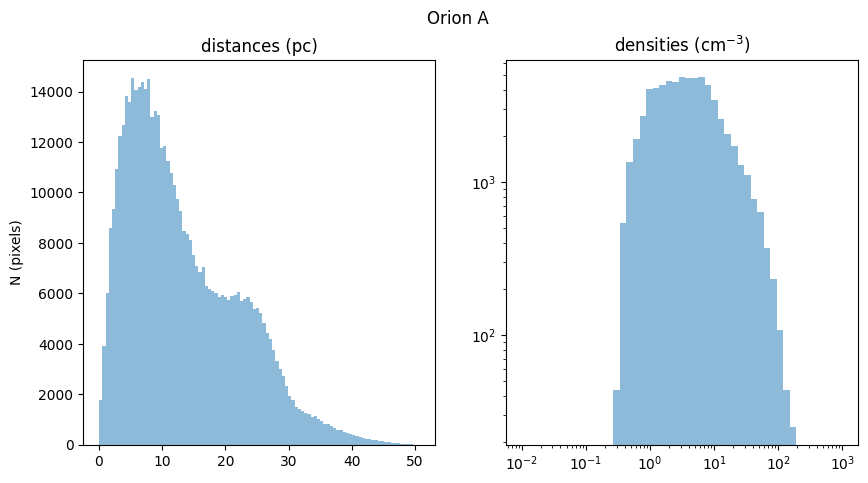

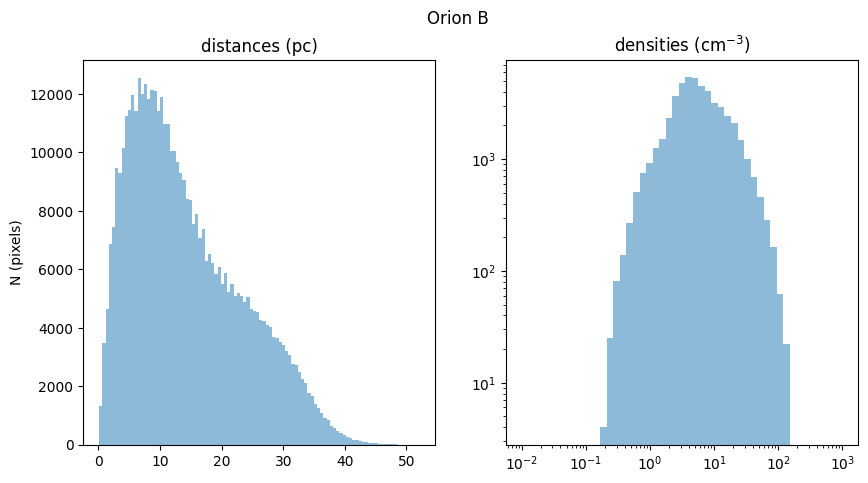

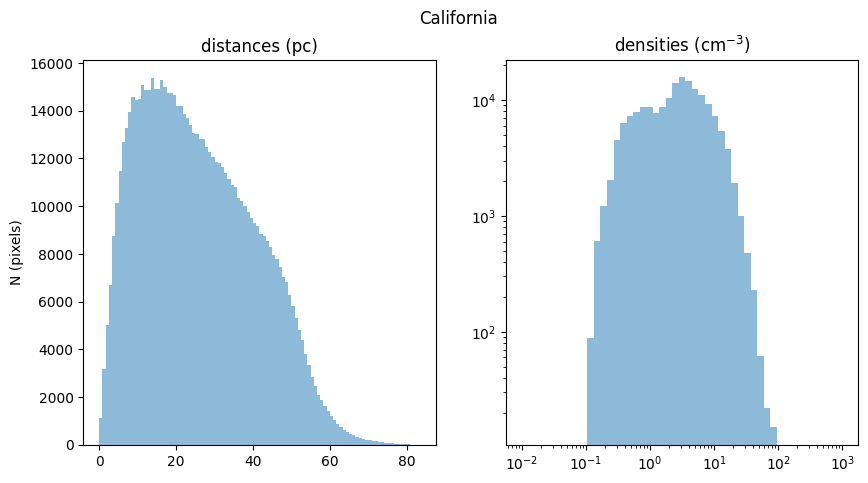

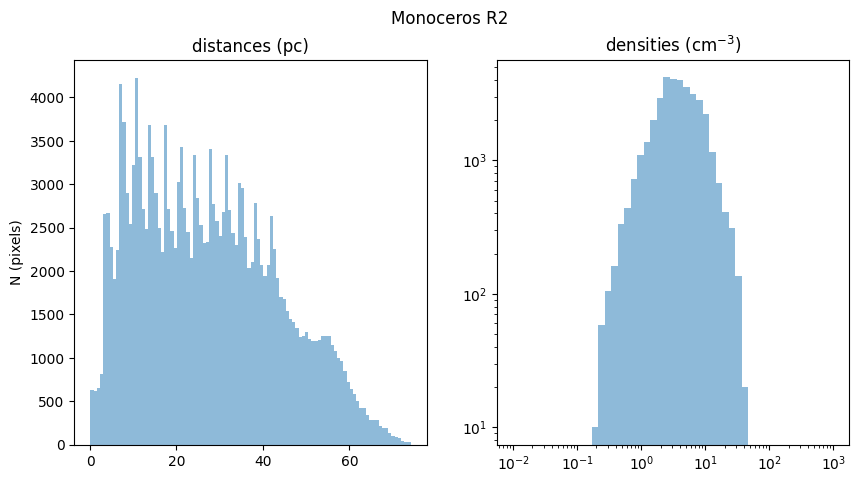

[None, None, None, None, None, None, None]

In [ ]:
[histogram(i,r) for i,r in zip(og_if_clouds,lewis_rs)]

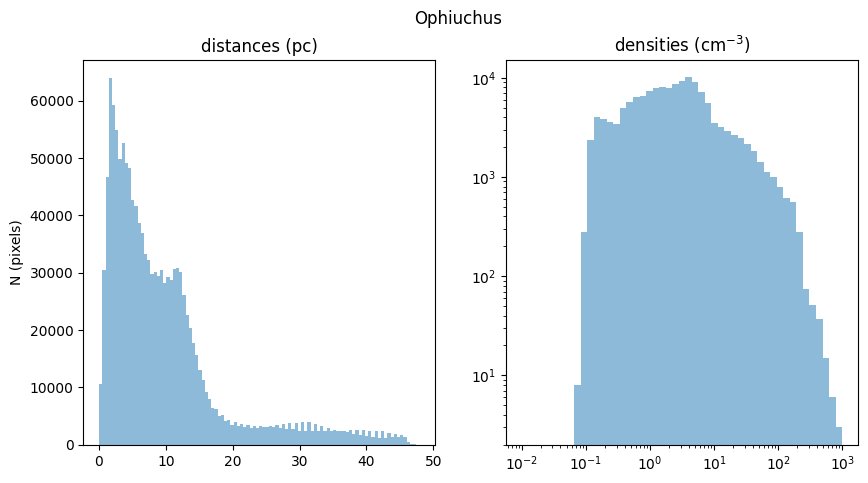

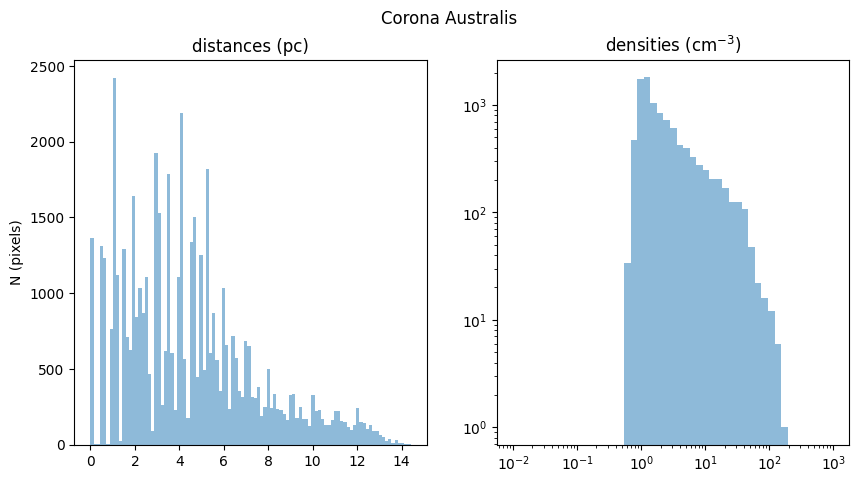

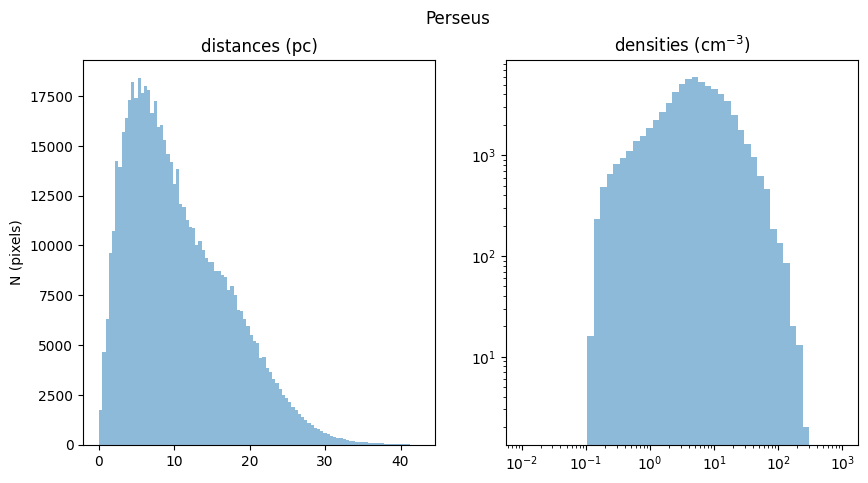

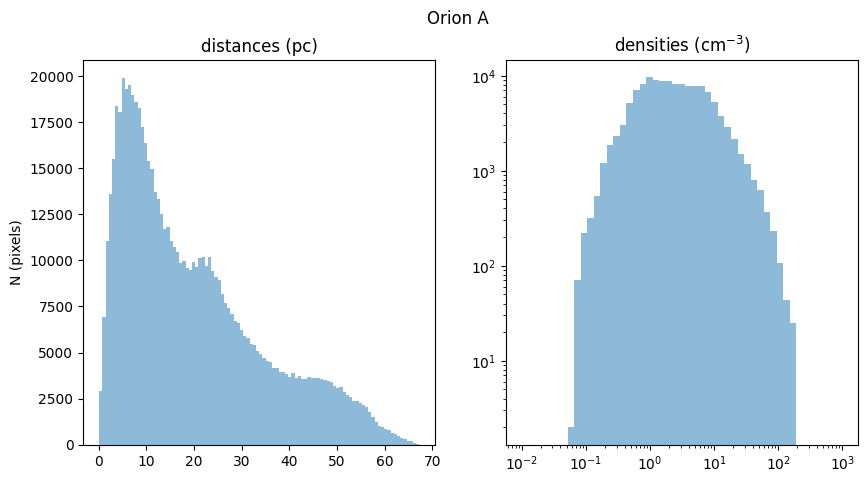

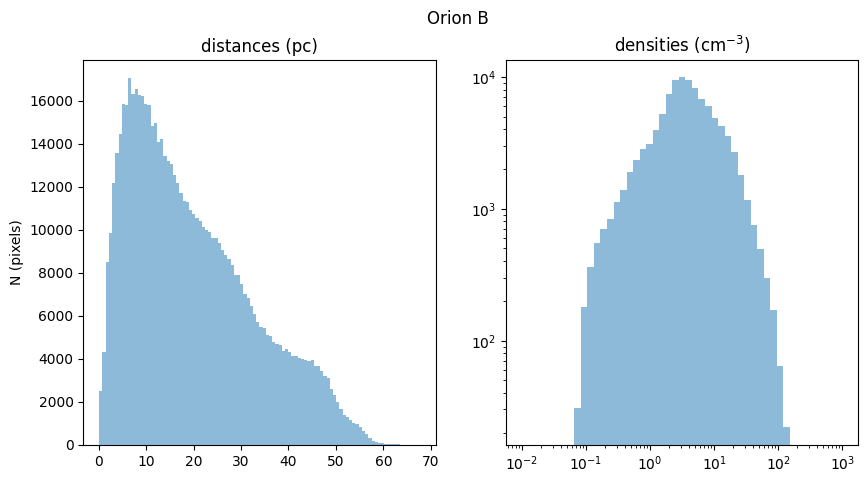

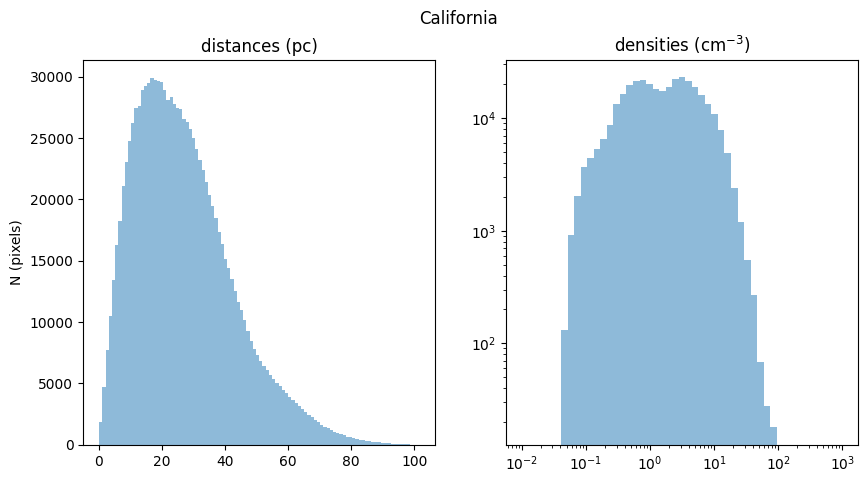

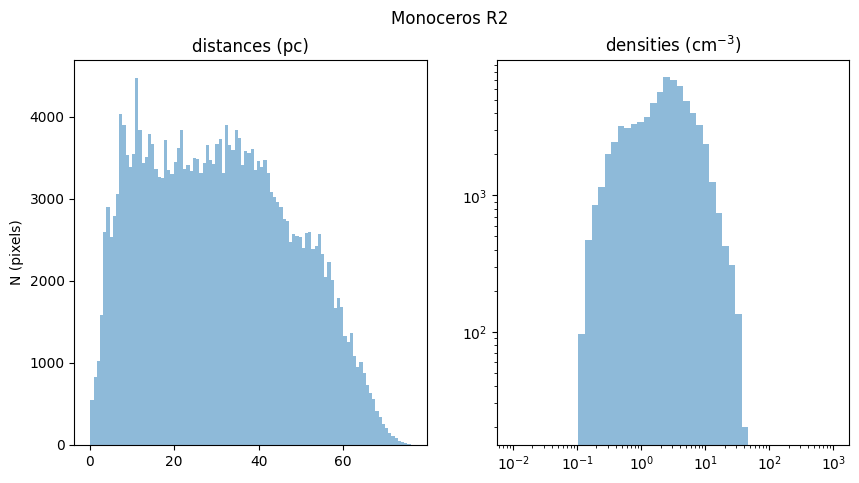

[None, None, None, None, None, None, None]

In [ ]:
[histogram(i,2*r) for i,r in zip(og_if_clouds,lewis_rs)]